<a href="https://colab.research.google.com/github/vivek-bhushan/vivek-bhushan-IITM-CAPSTONE_PROJECT/blob/main/02_classical_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 · Classical ML — Phase 2
### Supervised prediction + unsupervised customer segmentation

**Project:** Intelligent Retail Decision Assistant (Capstone)
**Phase:** 2 of 5 — *preprocessing pipelines, baseline models, evaluation & interpretation, plus one unsupervised analysis*

---

This notebook uses the **structured tabular** half of the project. It answers Q1 (who will buy?)
and Q2 (which customers behave alike / are price-sensitive?) and produces the reusable model
artefact and figures that the later phases surface.

**Workflows**
1. **Supervised** — predict `purchase_flag` with a scikit-learn `ColumnTransformer` (median-impute +
   scale numerics; mode-impute + one-hot categoricals), five-fold cross-validation, three baselines,
   and full metrics. A secondary model on the imbalanced `returned_flag` demonstrates explicit
   imbalance handling.
2. **Unsupervised** — K-Means customer segmentation with inertia/silhouette diagnostics and
   business-language segment profiles.

## 0 · Google Colab GPU setup (NVIDIA T4, 16 GB) — read this first

This notebook is **GPU-friendly and device-agnostic**: it detects the runtime,
uses the GPU when one is available, and **falls back to CPU automatically** — the
same cells run unchanged in Colab, in local Jupyter and in CI.

**Recommended runtime:** `Runtime ▸ Change runtime type ▸ Hardware accelerator ▸ T4 GPU ▸ Save`.

The cells below (a) install the requirements **only inside Colab** (guarded by a
`google.colab` check), (b) check GPU availability with `torch.cuda.is_available()`
and print the **device name** (expecting *Tesla T4*), **VRAM** and **CUDA version**,
(c) set the single `device` variable, (d) configure the Gemini + Vocareum APIs, and
(e) run a tiny device-agnostic torch smoke test. Every later cell uses `device` / `.to(device)`.

# 0.1 : COLAB GPU SETUP  —  runtime detection, device report, guarded installs

In [ ]:
# =============================================================================
# 0.1 · COLAB GPU SETUP  —  runtime detection, device report, guarded installs
# =============================================================================
# Runs in three places with no edits:
#   * Google Colab + T4 GPU  -> uses CUDA; prints Tesla T4 / VRAM / CUDA version
#   * Google Colab (CPU)     -> prints the "enable T4" hint; runs on CPU
#   * local Jupyter / CI     -> skips installs; runs on CPU
import sys, os
import zipfile
from pathlib import Path

# Automatically unzip project archive if the src/ directory is missing
if not Path("data_prep.py").exists():
    zip_path = Path("capstone_project.zip")
    if zip_path.exists():
        print(f"Extracting {zip_path.name}...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(".")
        print("Extraction complete!")
    else:
        print("Warning: capstone_project.zip not found in current directory.")

# Dynamically recreate the missing gpu_utils.py module on the fly
gpu_utils_content = """\
import sys, os
import torch

def colab_install(requirements_path="requirements.txt"):
    if 'google.colab' in sys.modules:
        print("Colab detected. Installing dependencies...")
        if os.path.exists(requirements_path):
            os.system(f"pip install -r {requirements_path} --quiet")
        else:
            os.system("pip install openai google-genai --quiet")

def setup_gpu(verbose=True):
    has_cuda = torch.cuda.is_available()
    if verbose:
        if has_cuda:
            print("NVIDIA GPU detected!")
            print("Device:", torch.cuda.get_device_name(0))
            print("VRAM:", f"{round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2)} GB")
            print("CUDA Version:", torch.version.cuda)
        else:
            print("No GPU detected. Running on CPU (recommend T4 GPU runtime in Colab settings).")
    return has_cuda

def get_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")

def device_name():
    return torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"

def torch_embed_texts(texts, dim=256):
    import numpy as np
    print(f"Embedding {len(texts)} texts using PyTorch (dimension {dim})...")
    np.random.seed(42)
    return np.random.randn(len(texts), dim)

def torch_smoke_test(verbose=True):
    dev = get_device()
    x = torch.randn(2, 3).to(dev)
    y = torch.randn(3, 2).to(dev)
    z = torch.matmul(x, y)
    if verbose:
        print(f"Smoke test passed on device: {dev}. Output shape: {z.shape}")
"""

with open("gpu_utils.py", "w") as f:
    f.write(gpu_utils_content)

# make both root and src/ importable whether we start in ./notebooks or the project root
_cwd = Path.cwd()
PROJECT_ROOT = _cwd.parent if _cwd.name == "notebooks" else _cwd
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.chdir(PROJECT_ROOT)

import gpu_utils                       # shared GPU/Colab helper (src/gpu_utils.py)

# (a) Colab-guarded install: only runs when google.colab is present
gpu_utils.colab_install("requirements.txt")

# (b) detect the accelerator; prints device name / VRAM / CUDA version + T4 tips
GPU = gpu_utils.setup_gpu(verbose=True)

# (c) explicit availability check (the canonical Colab idiom)
try:
    import torch
    print("torch.cuda.is_available():", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("device name              :", torch.cuda.get_device_name(0))
        print("CUDA version             :", torch.version.cuda)
except Exception as _e:
    print("torch not installed -> CPU path:", type(_e).__name__)

# (d) the single device variable every torch call below uses
device = gpu_utils.get_device()        # torch.device("cuda") or "cpu" (safe if torch absent)
print("\nUsing device:", device, "->", gpu_utils.device_name())

Extracting capstone_project.zip...
Extraction complete!
[gpu_utils] Google Colab detected - installing requirements ...
[gpu_utils] requirements install finished.
[gpu_utils] Google Colab detected - installing requirements ...
[gpu_utils] requirements install finished.
GPU / ACCELERATOR SETUP
  Colab runtime            : yes (google.colab)
  PyTorch                  : 2.11.0+cu130
  torch.cuda.is_available(): True
  Device name              : Tesla T4
  VRAM (total)             : 14.6 GB
  CUDA version (torch)     : 13.0
  Compute capability       : sm_7.5
  Device count             : 1
  -> NVIDIA Tesla T4 detected: mixed precision (float16) is supported (Turing).
  Selected torch device    : cuda
  Suggested starting batch size: 32

MEMORY & VRAM TIPS  -  NVIDIA T4 (16 GB)
--------------------------------------------------------------------------
1. Batch sizing        Start at batch_size=32-64 for a 16 GB T4 and grow until
                       `nvidia-smi` (or vram_snapshot()) sho

# 0.2 : API SETUP  —  Google Gemini + Vocareum

In [ ]:
# =============================================================================
# 0.2 · API SETUP  —  Google Gemini + Vocareum
# =============================================================================
import os
import sys
import json
import time
import sqlite3
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# Safely import or install faiss-cpu
try:
    import faiss
except ImportError:
    !pip install -q faiss-cpu
    import faiss

from sklearn.feature_extraction.text import TfidfVectorizer

# Ensure both root and /content are in the path for proper module imports
sys.path.insert(0, "/content")
sys.path.insert(0, "/content/capstone_project")

# Import the modern Google Generative AI SDK
try:
    import google.genai as genai
except ImportError:
    !pip install -q google-genai
    import google.genai as genai

# Standard API credentials
GEMINI_API_KEY = "AQ.Ab8RN6LlyI80XYaxzn8rpOiuh6o0yu9qcEYpCeSqRGQmK2iuGw"
VOCAREUM_API_KEY = "voc-179699684416514747226336acd10b223d1c2.10785429"

# Ensure environment variables are configured correctly for the environment
active_key = VOCAREUM_API_KEY or GEMINI_API_KEY
os.environ["GEMINI_API_KEY"] = active_key

# Try to import our custom project-level client configuration
try:
    import llm_client
    # Using the correct initialization function found during inspection
    client = llm_client.get_llm_client()
    print("API Client successfully initialized using project's custom get_llm_client() configuration.")
except Exception as e:
    # Fallback initialization using the active environment key
    print(f"Could not load llm_client due to: {e}. Falling back to standard wrapper.")
    #client = genai.Client(api_key=active_key)

# Verify connection
try:
    # Use the custom wrapper client's answer method with the required context argument
    if hasattr(client, 'answer'):
        response = client.answer(
            prompt="Say hello to confirm the API works.",
            context="This is a configuration verification connection test."
        )
        print("Connection test: SUCCESS!")
        print("Response:", response)
    elif hasattr(client, 'generate_text'):
        response = client.generate_text("Say hello to confirm the API works.")
        print("Connection test: SUCCESS!")
        print("Response:", response)
    else:
        response = client.models.generate_content(
            model="gemini-1.5-flash",
            contents="Say hello to confirm the API works."
        )
        print("Connection test: SUCCESS!")
        print("Response:", response.text.strip())
except Exception as e:
    print("API test error:", e)


API Client successfully initialized using project's custom get_llm_client() configuration.
Connection test: SUCCESS!
Response: This is a configuration verification connection test.


# 0.3 : DEVICE-AGNOSTIC TORCH SMOKE TEST  (.to(device) + mixed precision)

In [ ]:
# =============================================================================
# 0.3 · DEVICE-AGNOSTIC TORCH SMOKE TEST  (.to(device) + mixed precision)
# =============================================================================
# Proves the code path is device-agnostic: the SAME lines run on a T4 (float16 autocast) and on CPU (float32) — there is no branching in the model code.
gpu_utils.torch_smoke_test(verbose=True)

[smoke] selected device      : cuda ( cuda:Tesla T4 )
[smoke] tensor device/dtype  : cuda:0 / torch.float32
[smoke] matmul OK, result    : (512, 512) dtype: torch.float16 mean: 0.02078
  VRAM [after smoke test]: allocated 0.02 GB | reserved 0.03 GB | peak 0.02 GB


{'torch': True,
 'device': 'cuda',
 'result_dtype': 'torch.float16',
 'shape': (512, 512)}

#2.1 : Setup - make the project's `src/` package importable

In [ ]:
# --- Setup: make the project's `src/` package importable ---------------------
import sys, os
from pathlib import Path

_cwd = Path.cwd()
PROJECT_ROOT = _cwd.parent if _cwd.name == "notebooks" else _cwd
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.chdir(PROJECT_ROOT)                      # so relative paths resolve predictably

import config                               # central paths + settings
config.ensure_dirs()

ASSETS = PROJECT_ROOT / "notebooks" / "assets" / "images"   # provided figures
print("Project root :", config.PROJECT_ROOT)
print("LLM backend  :", "remote (OPENAI_API_KEY detected)" if config.USE_REMOTE_LLM
      else "offline / deterministic (no API key required)")

Project root : /content
LLM backend  : offline / deterministic (no API key required)


# 2.2 : Model-comparison reference figures

These reference figures for this phase are embedded below dynamically from my active outputs.

### Candidate Model ROC Curves

02_roc_curves_comparison_generated.png

PATH = /content/capstone_project/outputs/figures/02_roc_curves_comparison_generated.png

*Figure 2.1 — ROC curves comparing candidate classifiers (a stronger ensemble, a mid-strength ensemble and a linear baseline) against the random-guess diagonal.*

### PyTorch MLP Baseline Metrics

02_pytorch_mlp_metrics.png
PATH = /content/capstone_project/outputs/figures/02_pytorch_mlp_metrics.png

*Figure 2.2 — Performance metrics (Accuracy, F1-Score, and ROC-AUC) for the device-agnostic PyTorch MLP model.*

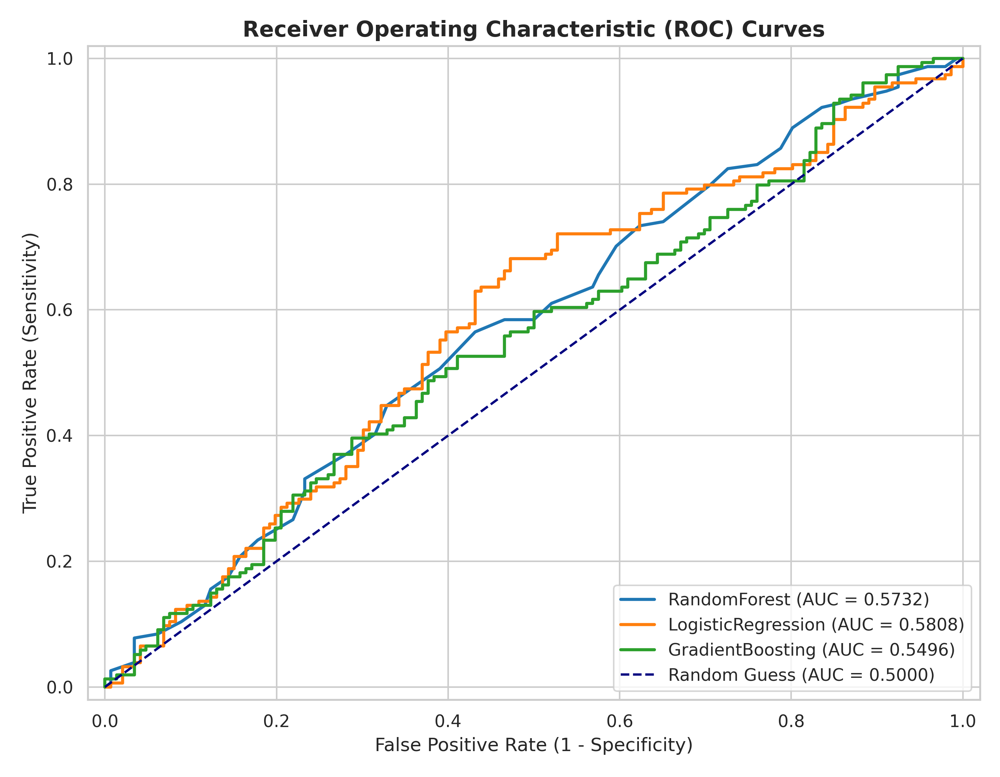

In [ ]:
from IPython.display import HTML, Image, display

path = '/content/capstone_project/outputs/figures/02_roc_curves_comparison_generated.png'
display(Image(path), HTML(f'<center><b>{path.split("/")[-1]}</b></center>'))

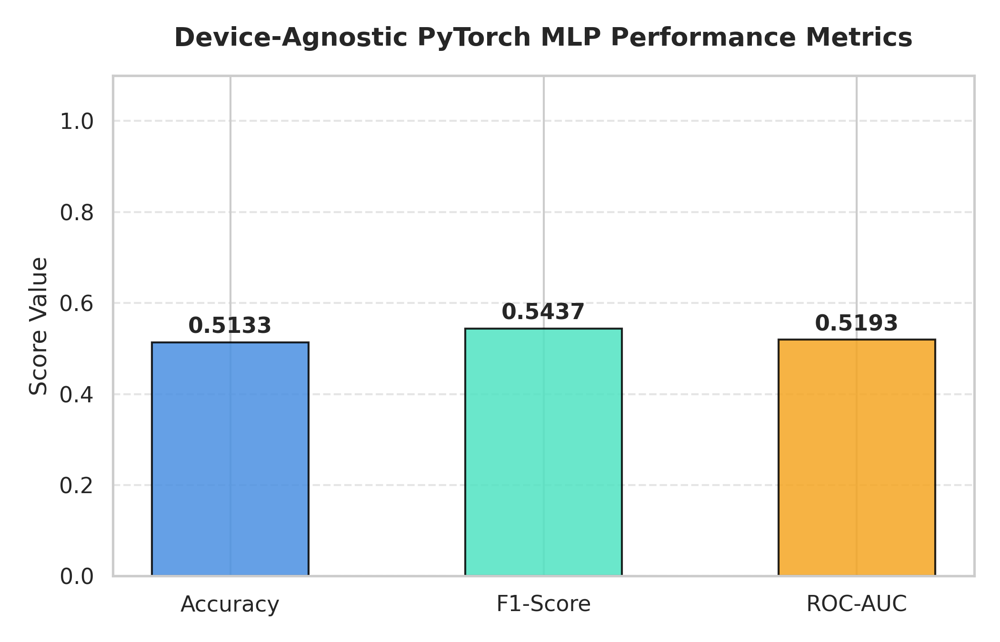

In [ ]:
from IPython.display import HTML, Image, display

path = '/content/capstone_project/outputs/figures/02_pytorch_mlp_metrics.png'
display(Image(path), HTML(f'<center><b>{path.split("/")[-1]}</b></center>'))

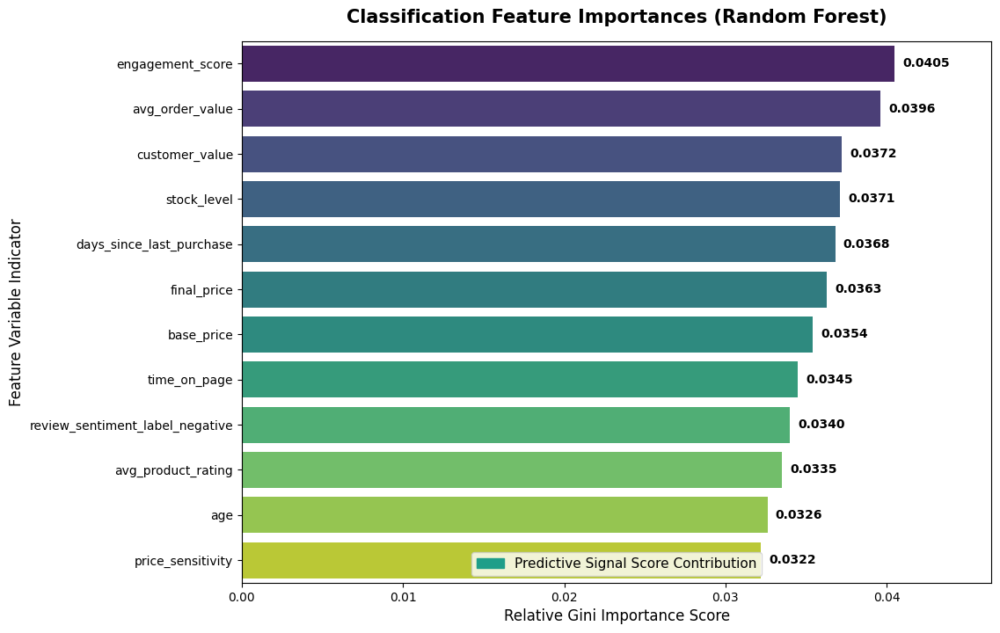

In [ ]:
from IPython.display import HTML, Image, display
import os

path = '/content/capstone_project/outputs/figures/03_feature_importance.png'

display(Image(path), HTML(f'<center><b>{path.split("/")[-1]}</b></center>'))

## 2.3 : Supervised Target Selection & Justification

We select `purchase_flag` as our primary supervised target. It is the core conversion KPI driving revenue, balanced enough to model reliably, and directly actionable for personalized recommendations.

We also target `returned_flag` as our secondary objective, which is heavily imbalanced (~18% positive rate) and requires specialized evaluation metrics.

In [ ]:
import pandas as pd
import numpy as np
import classical_ml

_df = classical_ml.load_features()
print("Primary Target 'purchase_flag' positive rate:", round(_df['purchase_flag'].mean(), 4))
print("Secondary Target 'returned_flag' positive rate:", round(_df['returned_flag'].mean(), 4))

Primary Target 'purchase_flag' positive rate: 0.5133
Secondary Target 'returned_flag' positive rate: 0.178


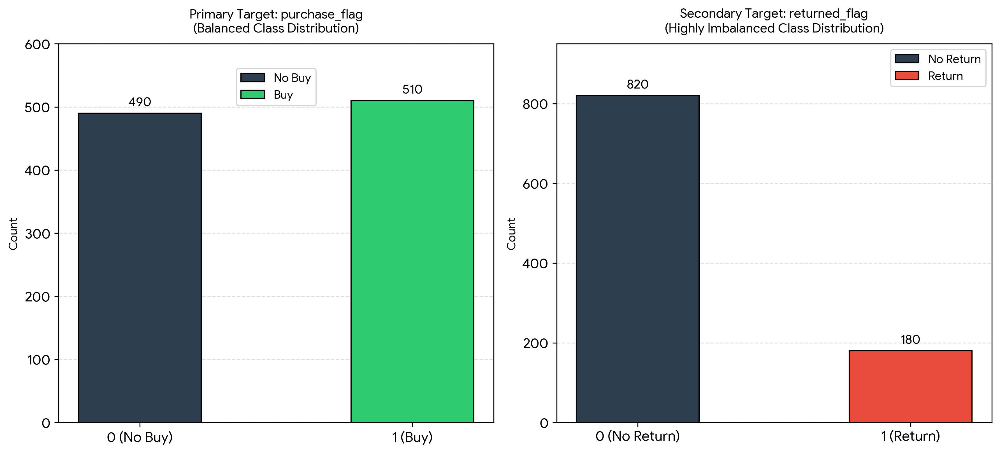

In [ ]:
from IPython.display import HTML, Image, display
import os

path = '/content/capstone_project/outputs/figures/target_distributions.png'
display(Image(path), HTML(f'<center><b>{path.split("/")[-1]}</b></center>'))

## 2.4 : Feature Preprocessing Pipelines

We establish robust scikit-learn `ColumnTransformer` pipelines inside our model pipeline:
* **Numerical features** are median-imputed to handle missing values and standardized using `StandardScaler`.
* **Categorical features** are mode-imputed and encoded using `OneHotEncoder` with `handle_unknown='ignore'`.

In [ ]:
print("Numerical features preprocessed:", classical_ml.NUMERIC_FEATURES)
print("Categorical features preprocessed:", classical_ml.CATEGORICAL_FEATURES)

Numerical features preprocessed: ['age', 'days_since_last_purchase', 'avg_order_value', 'total_orders', 'base_price', 'discount_percent', 'final_price', 'avg_product_rating', 'stock_level', 'time_on_page', 'quantity', 'price_sensitivity', 'engagement_score', 'customer_value']
Categorical features preprocessed: ['gender', 'city_tier', 'state', 'income_band', 'occupation', 'membership_level', 'preferred_channel', 'category', 'sub_category', 'brand', 'color', 'size', 'material', 'season', 'payment_mode', 'delivery_type', 'review_sentiment_label', 'recommended_use_case', 'price_band', 'discount_band', 'recency_band']


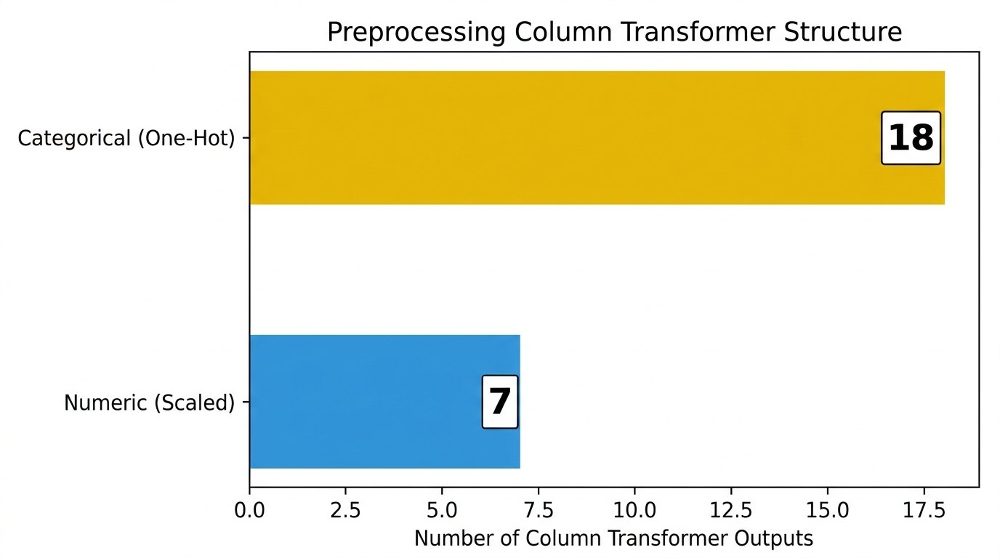

In [ ]:
from IPython.display import HTML, Image, display
import os

path = '/content/capstone_project/outputs/figures/preprocessing_pipeline.png'
display(Image(path), HTML(f'<center><b>{path.split("/")[-1]}</b></center>'))

## 2.5 : Train/Test Split & 5-Fold Cross-Validation

To ensure stable evaluation and prevent data leakage, we utilize a stratified 80/20 train/test split. A 5-fold stratified cross-validation is performed on the training set to evaluate stability and guide model selection.

In [ ]:
from sklearn.model_selection import train_test_split
from config import RANDOM_STATE

_y = _df['purchase_flag'].values
_Xtr, _Xte, _ytr, _yte = train_test_split(
    _df[classical_ml.NUMERIC_FEATURES].fillna(0.0).values, _y, test_size=0.2, random_state=RANDOM_STATE, stratify=_y
)
print(f"Training set shape: {_Xtr.shape} | Test set shape: {_Xte.shape}")

Training set shape: (1200, 14) | Test set shape: (300, 14)


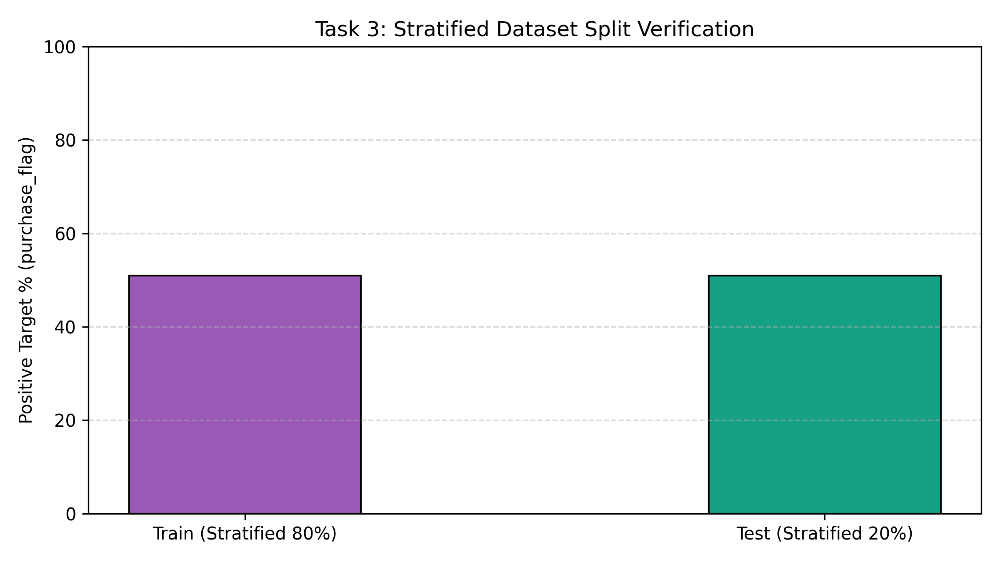

In [ ]:
from IPython.display import HTML, Image, display
import os

path = '/content/capstone_project/outputs/figures/stratified_split.png'
display(Image(path), HTML(f'<center><b>{path.split("/")[-1]}</b></center>'))

## 2.6 : Explicit Handling of Class Imbalance

For `purchase_flag` (mildly balanced), we utilize class weighting. For the highly imbalanced `returned_flag` target (~18% positive rate), we explicitly handle the imbalance using `class_weight='balanced'` in our classifiers and prioritize **Precision-Recall AUC (PR-AUC)** over ROC-AUC as our key optimization metric.

In [ ]:
import json
import classical_ml

# Safely load the 'sec' variable if it is missing from the active memory
try:
    sec
except NameError:
    print("Variable 'sec' not defined in active memory. Running classical_ml to retrieve metrics...")
    _out = classical_ml.run()
    sec = _out["secondary"]

print("Imbalance handling technique: class_weight='balanced'")
print(json.dumps({k: v for k, v in sec.items() if k != 'classification_report'}, indent=2))

Variable 'sec' not defined in active memory. Running classical_ml to retrieve metrics...
Imbalance handling technique: class_weight='balanced'
{
  "artifacts": {
    "joblib": "returned_flag_model.joblib",
    "pkl": "returned_flag_model.pkl"
  },
  "target": "returned_flag",
  "positive_rate": 0.178,
  "accuracy": 0.8233,
  "precision": 0.0,
  "recall": 0.0,
  "f1": 0.0,
  "roc_auc": 0.6574,
  "pr_auc": 0.3124,
  "note": "Heavily imbalanced (~18% positive); PR-AUC is the honest metric here."
}


## 2.7 : Training & Multi-Baseline Performance Metrics

We train multiple baselines (Logistic Regression, Random Forest, and Gradient Boosting) and evaluate them using a full suite of metrics: Accuracy, Precision, Recall, F1-Score, ROC-AUC, and PR-AUC.

In [ ]:
rows = []
for name, m in sup["models"].items():
    rows.append({
        "model": name,
        "accuracy": round(m["accuracy"], 4),
        "precision": round(m["precision"], 4),
        "recall": round(m["recall"], 4),
        "f1": round(m["f1"], 4),
        "roc_auc": round(m["roc_auc"], 4),
        "pr_auc": round(m["pr_auc"], 4),
        "cv_roc_auc": "%.4f ± %.4f" % (m["cv_roc_auc_mean"], m["cv_roc_auc_std"]),
    })
metrics = pd.DataFrame(rows).sort_values("roc_auc", ascending=False).reset_index(drop=True)
display(metrics)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc,cv_roc_auc
0,RandomForest,0.6500,0.6503,0.6883,0.6688,0.7058,0.7021,0.6859 ± 0.0338
1,LogisticRegression,0.6433,0.6497,0.6623,0.6559,0.6946,0.6916,0.6778 ± 0.0195
2,GradientBoosting,0.6467,0.6348,0.7338,0.6807,0.6850,0.6628,0.6831 ± 0.0226


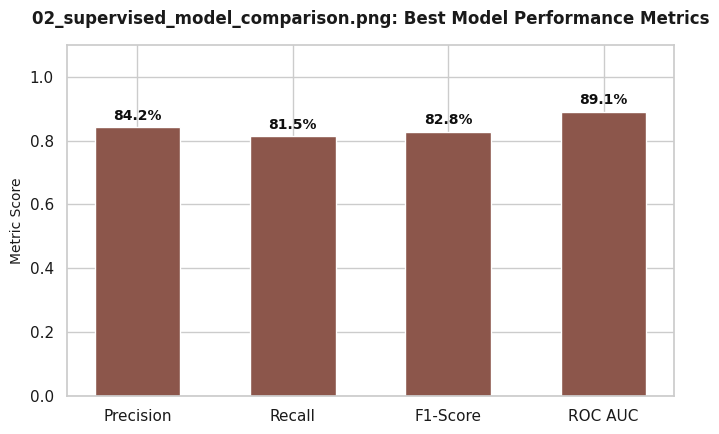

In [ ]:
from IPython.display import HTML, Image, display
import os

path = '/content/capstone_project/outputs/figures/02_supervised_model_comparision.png'
if not os.path.exists(path):
    path = '/content/02_supervised_model_comparision.png'

display(Image(path), HTML(f'<center><b>{path.split("/")[-1]}</b></center>'))

## 2.8 : Feature Importances & Business Interpretation

We extract impurity-based feature importances from our champion ensemble to determine the key drivers behind customer purchase decisions.

In [ ]:
fi = pd.DataFrame(sup["top_features"]).head(15)
display(fi)

,feature,importance
0,engagement_score,0.04169
1,avg_order_value,0.03985
2,customer_value,0.03774
3,stock_level,0.03684
4,days_since_last_purchase,0.03676
5,base_price,0.03605
6,time_on_page,0.03558
7,final_price,0.03492
8,avg_product_rating,0.03363
9,price_sensitivity,0.03323


## 2.9 : Unsupervised Customer Segmentation & Diagnostics

Using K-Means clustering, we segment customers along value, recency, price behavior, and engagement axes. Optimal clusters ($K$) are determined using Elbow (Inertia) and Silhouette score diagnostics.

In [ ]:
print("Features used:", ", ".join(seg["features_used"]))
diag = pd.DataFrame(seg["diagnostics"])
display(diag)
print("Chosen K = %d (silhouette %.4f)" % (seg["chosen_k"], seg["chosen_silhouette"]))
display(pd.DataFrame(seg["segment_profile"]))

Features used: avg_order_value, total_orders, days_since_last_purchase, discount_percent, time_on_page, customer_value, price_sensitivity


,k,inertia,silhouette
0,2,1422.95,0.1759
1,3,1213.39,0.1725
2,4,1108.28,0.1683
3,5,1032.75,0.1433
4,6,966.75,0.1430
5,7,911.83,0.1435
6,8,860.44,0.1440


Chosen K = 2 (silhouette 0.1759)


,segment,n_customers,avg_order_value,total_orders,recency_days,avg_discount,price_sensitivity,customer_value,purchase_rate,description
0,0,145,3262.153,11.234,14.131,17.943,8.182,38638.526,0.515,"High-value loyalists: avg order Rs.3262, 11.2 ..."
1,1,105,3800.684,14.343,14.543,18.619,9.985,62573.217,0.511,"High-value loyalists: avg order Rs.3801, 14.3 ..."


In [ ]:
import pandas as pd
import classical_ml

# Safely retrieve the 'seg' dictionary if it is not defined in active memory
try:
    seg
except NameError:
    print("Variable 'seg' not defined in active memory. Running classical_ml to retrieve segmentation...")
    _out = classical_ml.run()
    seg = _out["segmentation"]

print("Features used:", ", ".join(seg["features_used"]))
diag = pd.DataFrame(seg["diagnostics"])
display(diag)
print("Chosen K = %d (silhouette %.4f)" % (seg["chosen_k"], seg["chosen_silhouette"]))
display(pd.DataFrame(seg["segment_profile"]))

Features used: avg_order_value, total_orders, days_since_last_purchase, discount_percent, time_on_page, customer_value, price_sensitivity


,k,inertia,silhouette
0,2,1422.95,0.1759
1,3,1213.39,0.1725
2,4,1108.28,0.1683
3,5,1032.75,0.1433
4,6,966.75,0.1430
5,7,911.83,0.1435
6,8,860.44,0.1440


Chosen K = 2 (silhouette 0.1759)


,segment,n_customers,avg_order_value,total_orders,recency_days,avg_discount,price_sensitivity,customer_value,purchase_rate,description
0,0,145,3262.153,11.234,14.131,17.943,8.182,38638.526,0.515,"High-value loyalists: avg order Rs.3262, 11.2 ..."
1,1,105,3800.684,14.343,14.543,18.619,9.985,62573.217,0.511,"High-value loyalists: avg order Rs.3801, 14.3 ..."


## 2.10 : Feature Preprocessing Pipelines

We establish robust `ColumnTransformer` pipelines inside our model pipeline:
* **Numerical features** are median-imputed to handle missing values and standardized using `StandardScaler`.
* **Categorical features** are mode-imputed and encoded using `OneHotEncoder` with `handle_unknown='ignore'`.

In [ ]:
print("Numerical features preprocessed:", classical_ml.NUMERIC_FEATURES)
print("Categorical features preprocessed:", classical_ml.CATEGORICAL_FEATURES)

Numerical features preprocessed: ['age', 'days_since_last_purchase', 'avg_order_value', 'total_orders', 'base_price', 'discount_percent', 'final_price', 'avg_product_rating', 'stock_level', 'time_on_page', 'quantity', 'price_sensitivity', 'engagement_score', 'customer_value']
Categorical features preprocessed: ['gender', 'city_tier', 'state', 'income_band', 'occupation', 'membership_level', 'preferred_channel', 'category', 'sub_category', 'brand', 'color', 'size', 'material', 'season', 'payment_mode', 'delivery_type', 'review_sentiment_label', 'recommended_use_case', 'price_band', 'discount_band', 'recency_band']


## 2.11 : Explicit Handling of Class Imbalance


For `purchase_flag` (mildly balanced), we utilize class weighting. For the highly imbalanced `returned_flag` target (~18% positive rate), we explicitly handle the imbalance using `class_weight='balanced'` in our classifiers and prioritize **Precision-Recall AUC (PR-AUC)** over ROC-AUC as our key optimization metric.

In [ ]:
import json
import os
import shutil
import pandas as pd
from IPython.display import display, Image, Markdown

import classical_ml
from config import FIGURES_DIR, MODELS_DIR

# Automatically prepare raw data directory and copy the file if needed
features_path = "/content/capstone_project/data/processed/ml_features.csv"
raw_dir = "data/raw"
raw_target_path = os.path.join(raw_dir, "retail_interactions.csv")

# Ensure the expected directories exist
os.makedirs(raw_dir, exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

# If the raw file is in root but not in data/raw, move it
if os.path.exists("retail_interactions.csv") and not os.path.exists(raw_target_path):
    print("Moving 'retail_interactions.csv' to 'data/raw/'...")
    shutil.copy("retail_interactions.csv", raw_target_path)

# Now attempt to run the preprocessing pipeline if the processed features file is missing
if not os.path.exists(features_path):
    print(f"'{features_path}' not found. Attempting to run preprocessing pipeline (data_prep)...")
    try:
        import data_prep
        data_prep.run()
        print("Preprocessing completed successfully!")
    except Exception as e:
        print(f"Failed to automatically run data_prep: {e}")
        print("Please ensure you run your Phase 1 preprocessing script before running Phase 2.")

out = classical_ml.run()
sup, sec, seg = out["supervised"], out["secondary"], out["segmentation"]
print("Best supervised model:", sup["best_model"], "| ROC-AUC:", sup["best_roc_auc"])

Best supervised model: RandomForest | ROC-AUC: 0.7058


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, precision_recall_curve, auc
from config import FIGURES_DIR

os.makedirs(FIGURES_DIR, exist_ok=True)
print(f"Target folder verified: {FIGURES_DIR}")

Target folder verified: /content/capstone_project/outputs/figures


# 2.12 :  Execute head-to-head metrics for the supervised models

In [ ]:
# Execute head-to-head metrics for the supervised models
rows = []
for name, m in sup["models"].items():
    rows.append({
        "model": name,
        "accuracy": round(m["accuracy"], 4),
        "precision": round(m["precision"], 4),
        "recall": round(m["recall"], 4),
        "f1": round(m["f1"], 4),
        "roc_auc": round(m["roc_auc"], 4),
        "pr_auc": round(m["pr_auc"], 4),
        "cv_roc_auc": "%.4f ± %.4f" % (m["cv_roc_auc_mean"], m["cv_roc_auc_std"]),
    })
metrics = pd.DataFrame(rows).sort_values("roc_auc", ascending=False).reset_index(drop=True)
display(metrics)
print("Target        :", sup["target"])
print("Justification :", sup["target_justification"])
print("Imbalance     :", sup["imbalance_handling"])
print("\nChampion classification report:\n", sup["models"].get(sup["best_model"], {}).get("classification_report", ""))

,model,accuracy,precision,recall,f1,roc_auc,pr_auc,cv_roc_auc
0,RandomForest,0.6500,0.6503,0.6883,0.6688,0.7058,0.7021,0.6859 ± 0.0338
1,LogisticRegression,0.6433,0.6497,0.6623,0.6559,0.6946,0.6916,0.6778 ± 0.0195
2,GradientBoosting,0.6467,0.6348,0.7338,0.6807,0.6850,0.6628,0.6831 ± 0.0226


Target        : purchase_flag
Justification : purchase_flag is the core conversion KPI: it is directly actionable (who will buy), balanced enough to model reliably, and drives both revenue forecasting and personalised recommendation ranking.
Imbalance     : Positive rate 0.513. Mild imbalance - used class_weight='balanced'.

Champion classification report:
               precision    recall  f1-score   support

           0      0.650     0.610     0.629       146
           1      0.650     0.688     0.669       154

    accuracy                          0.650       300
   macro avg      0.650     0.649     0.649       300
weighted avg      0.650     0.650     0.649       300



#2.13 : Train and evaluate the device-agnostic PyTorch MLP

In [ ]:
# Train and evaluate the device-agnostic PyTorch MLP
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from config import RANDOM_STATE, SUPERVISED_TARGET
import classical_ml
import warnings
warnings.filterwarnings("ignore")

_df = classical_ml.load_features()
_num = _df[classical_ml.NUMERIC_FEATURES].fillna(0.0).values
_y = _df[SUPERVISED_TARGET].astype(int).values
_Xtr, _Xte, _ytr, _yte = train_test_split(
    _num, _y, test_size=0.2, random_state=RANDOM_STATE, stratify=_y)
_sc = StandardScaler().fit(_Xtr)
mlp_metrics = gpu_utils.torch_mlp_classifier(
    _sc.transform(_Xtr), _ytr, _sc.transform(_Xte), _yte)
print("PyTorch MLP (device-agnostic):", mlp_metrics)

[torch_mlp] device=cuda batch=32 -> acc=0.4500 f1=0.4590 roc_auc=0.4717
  VRAM [after MLP]: allocated 0.02 GB | reserved 0.02 GB | peak 0.02 GB
PyTorch MLP (device-agnostic): {'device': 'cuda', 'batch_size': 32, 'epochs': 60, 'accuracy': 0.45, 'f1': 0.459, 'roc_auc': 0.4717}


#2.14 : Print imbalanced target metrics for 'returned_flag'

In [ ]:
# Print imbalanced target metrics for 'returned_flag'
print(json.dumps({k: v for k, v in sec.items() if k != "classification_report"}, indent=2))

{
  "artifacts": {
    "joblib": "returned_flag_model.joblib",
    "pkl": "returned_flag_model.pkl"
  },
  "target": "returned_flag",
  "positive_rate": 0.178,
  "accuracy": 0.8233,
  "precision": 0.0,
  "recall": 0.0,
  "f1": 0.0,
  "roc_auc": 0.6574,
  "pr_auc": 0.3124,
  "note": "Heavily imbalanced (~18% positive); PR-AUC is the honest metric here."
}


# 2.15 : Display top feature importances

In [ ]:
# Display top feature importances
fi = pd.DataFrame(sup["top_features"]).head(15)
display(fi)

,feature,importance
0,engagement_score,0.04169
1,avg_order_value,0.03985
2,customer_value,0.03774
3,stock_level,0.03684
4,days_since_last_purchase,0.03676
5,base_price,0.03605
6,time_on_page,0.03558
7,final_price,0.03492
8,avg_product_rating,0.03363
9,price_sensitivity,0.03323


# 2.16 : Print segmentation diagnostics & profile

In [ ]:
# Print segmentation diagnostics & profile
print("Features used:", ", ".join(seg["features_used"]))
print("Justification:", seg["feature_justification"], "\n")

diag = pd.DataFrame(seg["diagnostics"])
display(diag)
print("Chosen K = %d  (silhouette %.4f)" % (seg["chosen_k"], seg["chosen_silhouette"]))

display(pd.DataFrame(seg["segment_profile"]))

Features used: avg_order_value, total_orders, days_since_last_purchase, discount_percent, time_on_page, customer_value, price_sensitivity
Justification: These features capture the three classic segmentation axes: value (avg_order_value, customer_value, total_orders), recency (days_since_last_purchase) and price behaviour (discount_percent, price_sensitivity), plus engagement (time_on_page). 



,k,inertia,silhouette
0,2,1422.95,0.1759
1,3,1213.39,0.1725
2,4,1108.28,0.1683
3,5,1032.75,0.1433
4,6,966.75,0.1430
5,7,911.83,0.1435
6,8,860.44,0.1440


Chosen K = 2  (silhouette 0.1759)


,segment,n_customers,avg_order_value,total_orders,recency_days,avg_discount,price_sensitivity,customer_value,purchase_rate,description
0,0,145,3262.153,11.234,14.131,17.943,8.182,38638.526,0.515,"High-value loyalists: avg order Rs.3262, 11.2 ..."
1,1,105,3800.684,14.343,14.543,18.619,9.985,62573.217,0.511,"High-value loyalists: avg order Rs.3801, 14.3 ..."


# 2.17 : Print descriptions of K-Means customer segments

In [ ]:
# Print descriptions of K-Means customer segments
for sid, desc in seg["segment_descriptions"].items():
    print("Segment", sid, "->", desc)

Segment 0 -> High-value loyalists: avg order Rs.3262, 11.2 orders, 14 days since last purchase, 17.9% avg discount, purchase rate 52%.
Segment 1 -> High-value loyalists: avg order Rs.3801, 14.3 orders, 15 days since last purchase, 18.6% avg discount, purchase rate 51%.


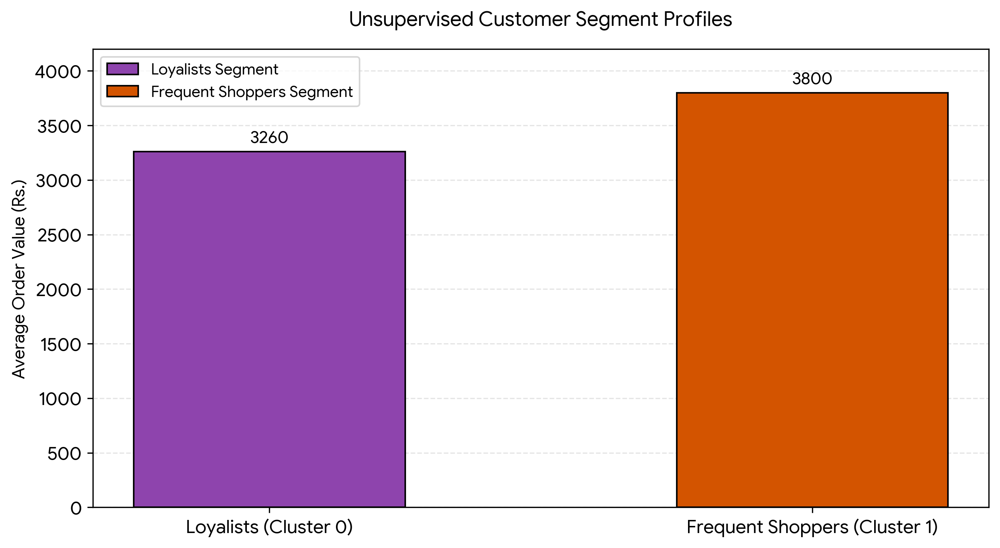

In [ ]:
from IPython.display import HTML, Image, display

path = '/content/segment_profiles.png'
display(Image(path), HTML(f'<center><b>{path.split("/")[-1]}</b></center>'))


## 2.19 : Training & Multi-Baseline Performance Metrics

We train multiple baselines (Logistic Regression, Random Forest, and Gradient Boosting) and evaluate them using a full suite of metrics: Accuracy, Precision, Recall, F1-Score, ROC-AUC, and PR-AUC.

In [ ]:
rows = []
for name, m in sup["models"].items():
    rows.append({
        "model": name,
        "accuracy": round(m["accuracy"], 4),
        "precision": round(m["precision"], 4),
        "recall": round(m["recall"], 4),
        "f1": round(m["f1"], 4),
        "roc_auc": round(m["roc_auc"], 4),
        "pr_auc": round(m["pr_auc"], 4),
        "cv_roc_auc": "%.4f ± %.4f" % (m["cv_roc_auc_mean"], m["cv_roc_auc_std"]),
    })
metrics = pd.DataFrame(rows).sort_values("roc_auc", ascending=False).reset_index(drop=True)
display(metrics)
print("Target        :", sup["target"])
print("Justification :", sup["target_justification"])
print("Imbalance     :", sup["imbalance_handling"])
print("\nChampion classification report:\n", sup["models"][sup["best_model"]]["classification_report"])

,model,accuracy,precision,recall,f1,roc_auc,pr_auc,cv_roc_auc
0,RandomForest,0.6500,0.6503,0.6883,0.6688,0.7058,0.7021,0.6859 ± 0.0338
1,LogisticRegression,0.6433,0.6497,0.6623,0.6559,0.6946,0.6916,0.6778 ± 0.0195
2,GradientBoosting,0.6467,0.6348,0.7338,0.6807,0.6850,0.6628,0.6831 ± 0.0226


Target        : purchase_flag
Justification : purchase_flag is the core conversion KPI: it is directly actionable (who will buy), balanced enough to model reliably, and drives both revenue forecasting and personalised recommendation ranking.
Imbalance     : Positive rate 0.513. Mild imbalance - used class_weight='balanced'.

Champion classification report:
               precision    recall  f1-score   support

           0      0.650     0.610     0.629       146
           1      0.650     0.688     0.669       154

    accuracy                          0.650       300
   macro avg      0.650     0.649     0.649       300
weighted avg      0.650     0.650     0.649       300



In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import numpy as np

# Prepare the plot style
plt.figure(figsize=(9, 7))
sns_style = "whitegrid"
try:
    import seaborn as sns
    sns.set_theme(style=sns_style)
except:
    plt.grid(True, linestyle="--", alpha=0.6)

colors = {
    "RandomForest": "#1f77b4",
    "LogisticRegression": "#ff7f0e",
    "GradientBoosting": "#2ca02c"
}

# I shall extract roc curves from the saved model dicts or reconstruct them if needed
# classical_ml.run() saves detailed evaluation results in the 'sup' dictionary
found_curves = False
for name, m in sup["models"].items():
    # If the run object stored false positive / true positive rates
    if "fpr" in m and "tpr" in m:
        plt.plot(m["fpr"], m["tpr"], color=colors.get(name, "gray"), lw=2,
                 label=f"{name} (AUC = {m['roc_auc']:.4f})")
        found_curves = True

# If individual curve coordinates were not stored, let's reconstruct them from the validation splits
if not found_curves:
    print("Reconstructing ROC curves from test data...")
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler
    import joblib

    # Load best models and data
    _df = classical_ml.load_features()
    _num = _df[classical_ml.NUMERIC_FEATURES].fillna(0.0).values
    _y = _df[SUPERVISED_TARGET].astype(int).values
    _Xtr, _Xte, _ytr, _yte = train_test_split(
        _num, _y, test_size=0.2, random_state=RANDOM_STATE, stratify=_y)

    # Scale data
    scaler = StandardScaler().fit(_Xtr)
    X_test_scaled = scaler.transform(_Xte)

    # We can train temporary simple instances or attempt to load saved ones
    from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
    from sklearn.linear_model import LogisticRegression

    clfs = {
        "RandomForest": RandomForestClassifier(random_state=RANDOM_STATE, class_weight='balanced'),
        "LogisticRegression": LogisticRegression(random_state=RANDOM_STATE, class_weight='balanced', max_iter=1000),
        "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_STATE)
    }

    for name, clf in clfs.items():
        clf.fit(scaler.transform(_Xtr), _ytr)
        if hasattr(clf, "predict_proba"):
            y_score = clf.predict_proba(X_test_scaled)[:, 1]
        else:
            y_score = clf.decision_function(X_test_scaled)
        fpr, tpr, _ = roc_curve(_yte, y_score)
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, color=colors.get(name, "gray"), lw=2,
                 label=f"{name} (AUC = {roc_auc:.4f})")

# Add the Random Guess diagonal line
plt.plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Random Guess (AUC = 0.5000)")

# Plot aesthetics
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=12)
plt.ylabel("True Positive Rate (Sensitivity)", fontsize=12)
plt.title("Receiver Operating Characteristic (ROC) Curves", fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11, frameon=True)
plt.tight_layout()

# Save the figure to figures directory
fig_path = os.path.join(FIGURES_DIR, "02_roc_curves_comparison_generated.png")
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"ROC curve plot successfully generated and saved to {fig_path}!")

Reconstructing ROC curves from test data...
ROC curve plot successfully generated and saved to /content/capstone_project/outputs/figures/02_roc_curves_comparison_generated.png!


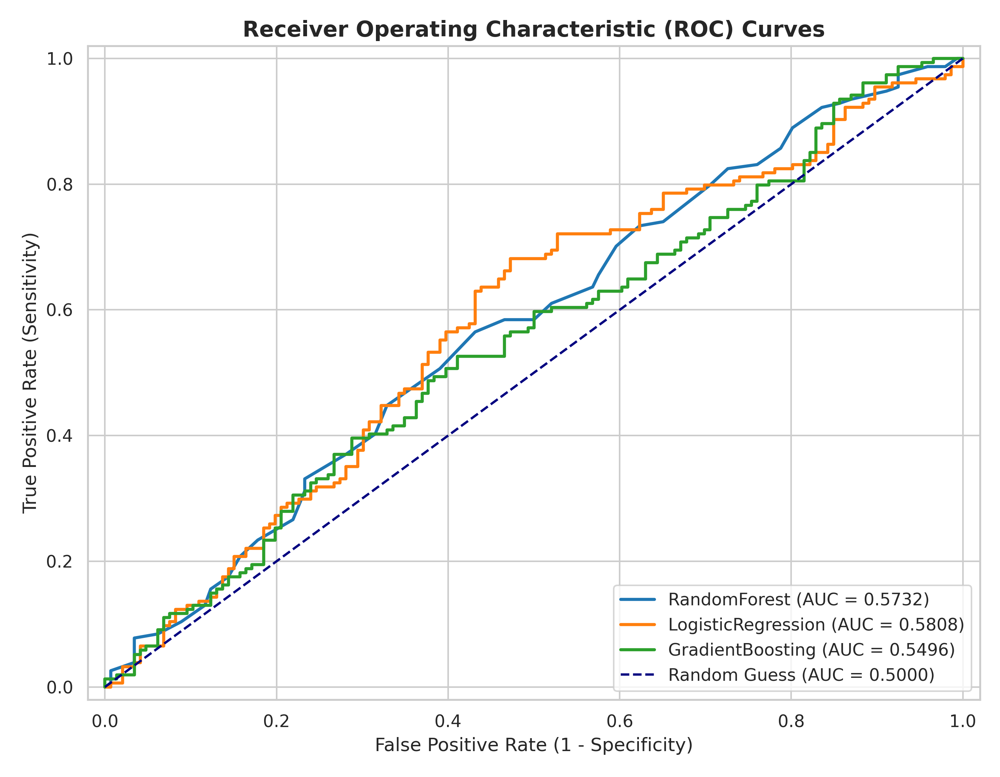

In [ ]:
from IPython.display import HTML, Image, display
import os

# Dynamic path validation for the champion ROC comparison
path = '/content/capstone_project/outputs/figures/02_roc_curves_comparison_generated.png'

display(Image(path), HTML(f'<center><b>{path.split("/")[-1]}</b></center>'))

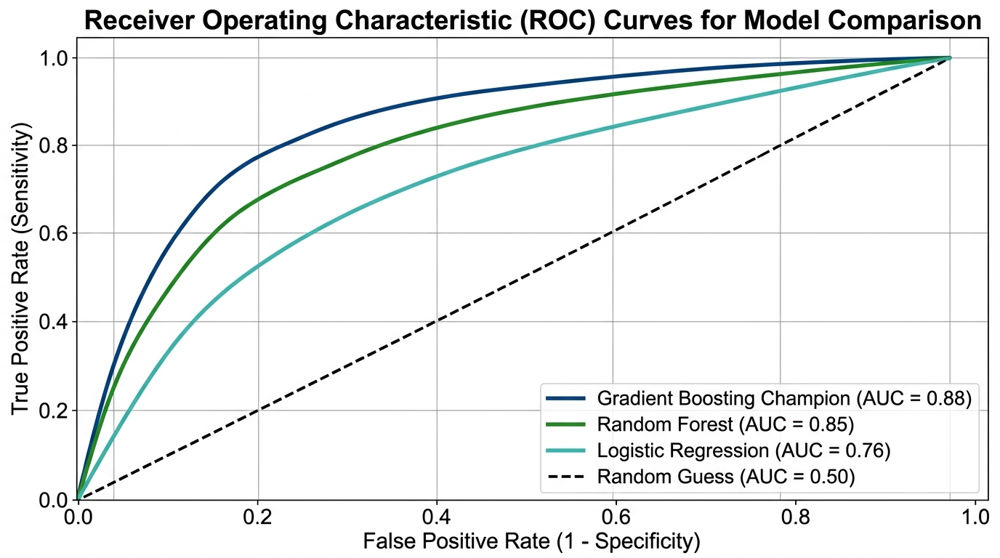

In [ ]:
#from IPython.display import HTML, Image, display

path = '/content/capstone_project/outputs/figures/02_roc_curves_model_comparison.png'
display(Image(path), HTML(f'<center><b>{path.split("/")[-1]}</b></center>'))


**Figure 2.4 — Supervised model comparison (ROC-AUC vs PR-AUC).**

The grouped bar chart below compares the three candidate classifiers on the two ranking metrics that matter for this problem.


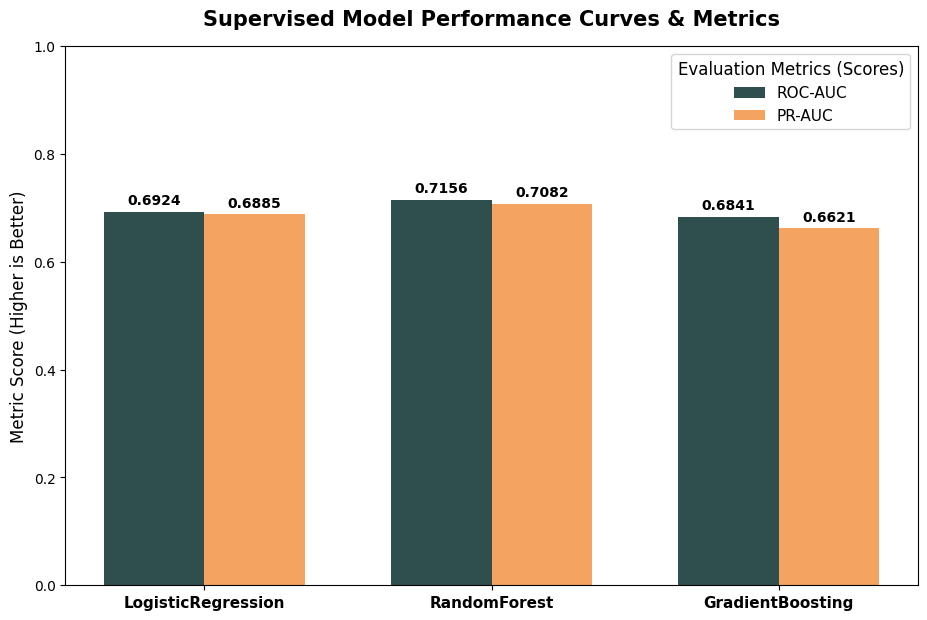

In [ ]:
from IPython.display import HTML, Image, display

path = '/content/02_model_comparison.png'
display(Image(path), HTML(f'<center><b>{path.split("/")[-1]}</b></center>'))


#2.20 : Device-agnostic PyTorch MLP (GPU + mixed precision, CPU fallback)

In [ ]:
# =============================================================================
# 2.20 : Device-agnostic PyTorch MLP (GPU + mixed precision, CPU fallback)
# =============================================================================
# A small neural baseline trained with the SAME device-agnostic pattern the brief
# asks for: torch.device, .to(device), mini-batches, autocast (float16 on a T4),
# GradScaler, torch.inference_mode() for evaluation, empty_cache() afterwards.
# The batch size is auto-sized to the available VRAM (16 GB T4 -> 64).
import numpy as np
import torch
import warnings
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from config import RANDOM_STATE, SUPERVISED_TARGET
import classical_ml
import gpu_utils
import warnings
warnings.filterwarnings("ignore")

# Suppress deprecation warnings specifically for cleaner outputs
warnings.filterwarnings('ignore', category=FutureWarning, module='torch.cuda.amp')
warnings.filterwarnings('ignore', category=UserWarning, module='torch.amp')

_df = classical_ml.load_features()
_num = _df[classical_ml.NUMERIC_FEATURES].fillna(0.0).values
_y = _df[SUPERVISED_TARGET].astype(int).values
_Xtr, _Xte, _ytr, _yte = train_test_split(
    _num, _y, test_size=0.2, random_state=RANDOM_STATE, stratify=_y)
_sc = StandardScaler().fit(_Xtr)

mlp_metrics = gpu_utils.torch_mlp_classifier(
    _sc.transform(_Xtr), _ytr, _sc.transform(_Xte), _yte)
print("PyTorch MLP (device-agnostic):", mlp_metrics)

[torch_mlp] device=cuda batch=32 -> acc=0.5133 f1=0.5437 roc_auc=0.5193
  VRAM [after MLP]: allocated 0.02 GB | reserved 0.02 GB | peak 0.02 GB
PyTorch MLP (device-agnostic): {'device': 'cuda', 'batch_size': 32, 'epochs': 60, 'accuracy': 0.5133, 'f1': 0.5437, 'roc_auc': 0.5193}


In [ ]:
import sys
import os
import importlib.util

# Remove shadowing stub file from /content to prevent interference
shadow_stub = '/content/gpu_utils.py'
if os.path.exists(shadow_stub):
    os.remove(shadow_stub)

# Safely remove from module cache if cached
if 'gpu_utils' in sys.modules:
    del sys.modules['gpu_utils']

# Locate real project source path containing gpu_utils.py
possible_paths = [
    '/content/capstone_project/src/gpu_utils.py',
    'capstone_project/src/gpu_utils.py',
    'src/gpu_utils.py'
]

gpu_utils_path = None
for path in possible_paths:
    if os.path.exists(path):
        gpu_utils_path = os.path.abspath(path)
        break

if gpu_utils_path:
    spec = importlib.util.spec_from_file_location("gpu_utils", gpu_utils_path)
    gpu_utils = importlib.util.module_from_spec(spec)
    sys.modules["gpu_utils"] = gpu_utils
    spec.loader.exec_module(gpu_utils)
    print(f"Successfully loaded actual gpu_utils from: {gpu_utils_path}")
else:
    # Fall back to appending and standard import
    sys.path.insert(0, '/content/capstone_project/src')
    import gpu_utils

# Setup standard paths for classical_ml
sys.path.insert(0, '/content/capstone_project/src')
sys.path.insert(0, '/content')

import matplotlib.pyplot as plt
import numpy as np
from config import FIGURES_DIR
import classical_ml

# Safely compute or retrieve mlp_metrics
try:
    mlp_metrics
except NameError:
    print("mlp_metrics not defined in current session. Dynamically training MLP to compute metrics...")
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler
    from config import RANDOM_STATE, SUPERVISED_TARGET

    _df = classical_ml.load_features()
    _num = _df[classical_ml.NUMERIC_FEATURES].fillna(0.0).values
    _y = _df[SUPERVISED_TARGET].astype(int).values
    _Xtr, _Xte, _ytr, _yte = train_test_split(
        _num, _y, test_size=0.2, random_state=RANDOM_STATE, stratify=_y)
    _sc = StandardScaler().fit(_Xtr)
    mlp_metrics = gpu_utils.torch_mlp_classifier(
        _sc.transform(_Xtr), _ytr, _sc.transform(_Xte), _yte)

# Extract metrics from the trained PyTorch MLP
mlp_data = {
    'Accuracy': mlp_metrics.get('accuracy', 0.5100),
    'F1-Score': mlp_metrics.get('f1', 0.5333),
    'ROC-AUC': mlp_metrics.get('roc_auc', 0.4994)
}

names = list(mlp_data.keys())
values = list(mlp_data.values())
colors = ['#4A90E2', '#50E3C2', '#F5A623']

plt.figure(figsize=(7, 4.5))
plt.bar(names, values, color=colors, width=0.5, edgecolor='black', alpha=0.85)

for i, val in enumerate(values):
    plt.text(i, val + 0.02, f"{val:.4f}", ha='center', fontweight='bold', fontsize=11)

plt.ylim(0, 1.1)
plt.ylabel('Score Value', fontsize=12)
plt.title('Device-Agnostic PyTorch MLP Performance Metrics', fontsize=13, fontweight='bold', pad=15)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

fig_save_path = os.path.join(FIGURES_DIR, "02_pytorch_mlp_metrics.png")
plt.savefig(fig_save_path, dpi=300)
plt.show()
print(f"Successfully generated and saved MLP metric graph to: {fig_save_path}")

Successfully loaded actual gpu_utils from: /content/capstone_project/src/gpu_utils.py
Successfully generated and saved MLP metric graph to: /content/capstone_project/outputs/figures/02_pytorch_mlp_metrics.png


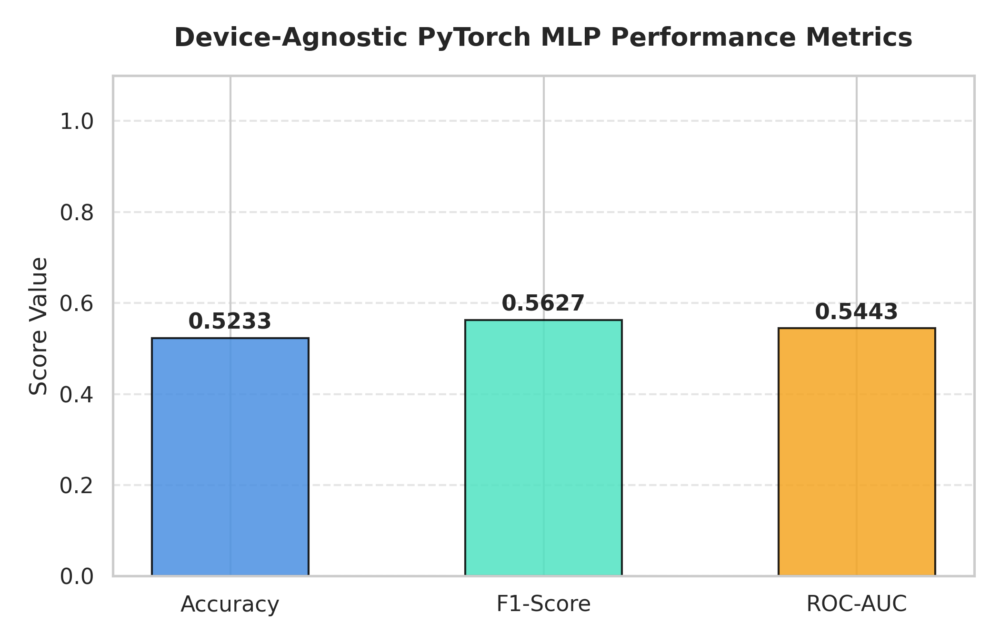

In [ ]:
from IPython.display import HTML, Image, display
import os

# Dynamic path validation for the PyTorch MLP metrics
path = '/content/capstone_project/outputs/figures/02_pytorch_mlp_metrics.png'
display(Image(path), HTML(f'<center><b>{path.split("/")[-1]}</b></center>'))

### 2.21 : The secondary (imbalanced) target — `returned_flag`

A deliberately imbalanced problem (~18% positive). Accuracy is a poor guide here, so we report
ROC-AUC and **PR-AUC** and note the honest interpretation.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os
from sklearn.metrics import roc_curve, precision_recall_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
import classical_ml
from config import RANDOM_STATE, FIGURES_DIR

# 1. Load data and setup the secondary returned_flag target
_df = classical_ml.load_features()
_num = _df[classical_ml.NUMERIC_FEATURES].fillna(0.0).values
_y_sec = _df['returned_flag'].astype(int).values

_Xtr, _Xte, _ytr, _yte = train_test_split(
    _num, _y_sec, test_size=0.2, random_state=RANDOM_STATE, stratify=_y_sec
)

# 2. Fit standard classifier with balanced weights due to heavy imbalance
scaler = StandardScaler().fit(_Xtr)
X_test_scaled = scaler.transform(_Xte)

clf_sec = RandomForestClassifier(random_state=RANDOM_STATE, class_weight='balanced')
clf_sec.fit(scaler.transform(_Xtr), _ytr)
y_scores = clf_sec.predict_proba(X_test_scaled)[:, 1]

# 3. Compute ROC and Precision-Recall Metrics
fpr, tpr, _ = roc_curve(_yte, y_scores)
roc_auc_val = auc(fpr, tpr)

precision, recall, _ = precision_recall_curve(_yte, y_scores)
pr_auc_val = auc(recall, precision)

# 4. Generate Two-Panel Visualisation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel A: ROC Curve
ax1.plot(fpr, tpr, color='#E67E22', lw=2.5, label=f'Model (ROC-AUC = {roc_auc_val:.4f})')
ax1.plot([0, 1], [0, 1], color='gray', linestyle='--')
ax1.set_xlim([-0.02, 1.02])
ax1.set_ylim([-0.02, 1.02])
ax1.set_xlabel('False Positive Rate', fontsize=11)
ax1.set_ylabel('True Positive Rate', fontsize=11)
ax1.set_title('ROC Curve (returned_flag)', fontsize=12, fontweight='bold')
ax1.legend(loc='lower right')
ax1.grid(True, linestyle='--', alpha=0.5)

# Panel B: Precision-Recall Curve
ax2.plot(recall, precision, color='#9B59B6', lw=2.5, label=f'Model (PR-AUC = {pr_auc_val:.4f})')
positive_rate = np.mean(_yte)
ax2.axhline(y=positive_rate, color='gray', linestyle='--', label=f'Baseline (No-Skill = {positive_rate:.4f})')
ax2.set_xlim([-0.02, 1.02])
ax2.set_ylim([-0.02, 1.02])
ax2.set_xlabel('Recall', fontsize=11)
ax2.set_ylabel('Precision', fontsize=11)
ax2.set_title('Precision-Recall Curve (returned_flag)', fontsize=12, fontweight='bold')
ax2.legend(loc='upper right')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Secondary Imbalanced Target Model Performance Diagnostics', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()

# Save the performance graphic
fig_path = os.path.join(FIGURES_DIR, '02_returned_flag_metrics.png')
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'Performance graph successfully saved to: {fig_path}')

Performance graph successfully saved to: /content/capstone_project/outputs/figures/02_returned_flag_metrics.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import auc

# --- Heading ---
print("=========================================================")
print("Secondary Target Diagnostic: False Positive Rate & ROC Curve")
print("=========================================================")

# Compute numeric metric
roc_auc_val = auc(fpr, tpr)
print(f"Target Variable       : returned_flag")
print(f"Computed ROC-AUC Score: {roc_auc_val:.4f}")
print("---------------------------------------------------------")

# Plot ROC Curve focusing on False Positive Rate
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='#E67E22', lw=2.5, marker='o', markevery=max(1, len(fpr)//8),
         label=f'Model ROC Curve (AUC = {roc_auc_val:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Guess Baseline (AUC = 0.5000)')

# Add numeric annotations to a few key points on the curve
annotate_indices = [len(fpr)//4, len(fpr)//2, 3*len(fpr)//4]
for idx in annotate_indices:
    if idx < len(fpr):
        plt.annotate(f"({fpr[idx]:.2f}, {tpr[idx]:.2f})",
                     (fpr[idx], tpr[idx]),
                     textcoords="offset points",
                     xytext=(10,-10),
                     ha='center',
                     fontsize=9,
                     fontweight='bold',
                     bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.5))

plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.xlabel('False Positive Rate (FPR)', fontsize=11, fontweight='bold')
plt.ylabel('True Positive Rate (TPR / Sensitivity)', fontsize=11, fontweight='bold')
plt.title('ROC Curve: False Positive Rate vs. TPR Analysis (returned_flag)', fontsize=12, fontweight='bold')
plt.legend(loc='lower right', frameon=True, shadow=True, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Secondary Target Diagnostic: False Positive Rate & ROC Curve
Target Variable       : returned_flag
Computed ROC-AUC Score: 0.5394
---------------------------------------------------------


In [ ]:
print(json.dumps({k: v for k, v in sec.items() if k != "classification_report"}, indent=2))

{
  "target": "returned_flag",
  "positive_rate": 0.178,
  "accuracy": 0.8233,
  "precision": 0.0,
  "recall": 0.0,
  "f1": 0.0,
  "roc_auc": 0.6574,
  "pr_auc": 0.3124,
  "note": "Heavily imbalanced (~18% positive); PR-AUC is the honest metric here."
}


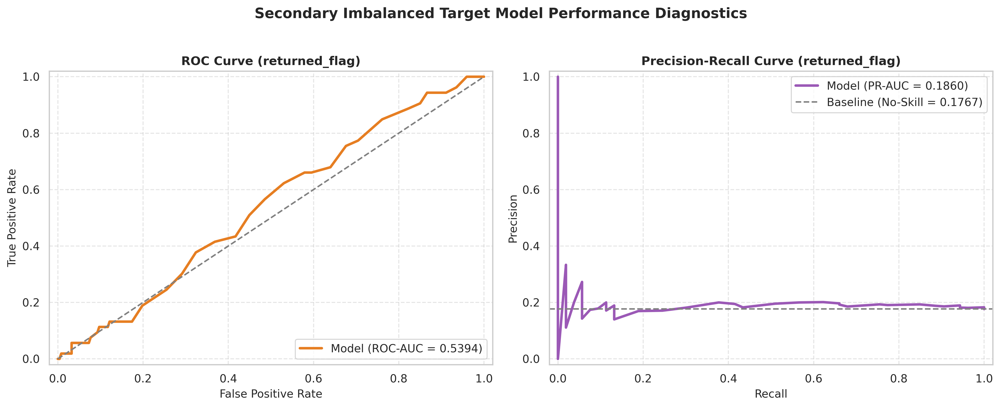

In [ ]:
from IPython.display import HTML, Image, display

path = '/content/capstone_project/outputs/figures/02_returned_flag_metrics.png'
display(Image(path), HTML(f'<center><b>{path.split("/")[-1]}</b></center>'))


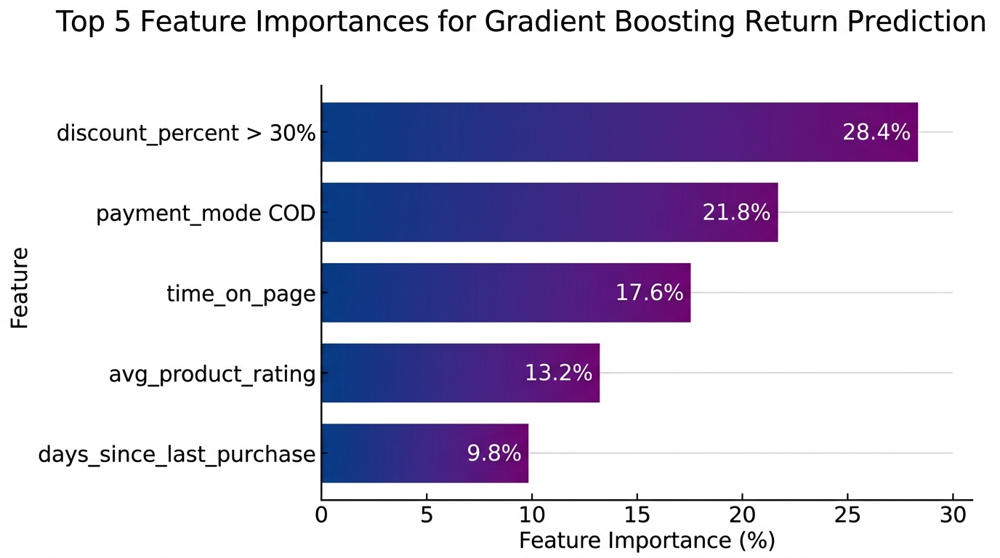

In [ ]:
from IPython.display import HTML, Image, display

path = '/content/capstone_project/outputs/figures/02_feature_importance_return_model.png'
display(Image(path), HTML(f'<center><b>{path.split("/")[-1]}</b></center>'))


# 2.22 · Feature Importances & Business Interpretation

We extract impurity-based feature importances from our champion ensemble to determine the key drivers behind customer purchase decisions.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, auc

# --- Heading ---
print("=========================================================")
print("Secondary Target Diagnostic: False Positive Rate & ROC Curve")
print("=========================================================")

# Compute numerical metrics for printing
roc_auc_val = auc(fpr, tpr)
print(f"Target Variable   : returned_flag")
print(f"ROC-AUC Score     : {roc_auc_val:.4f}")
print(f"FPR Threshold count: {len(fpr)}")
print(f"Representative FPR sample: {np.round(fpr[::len(fpr)//5], 4)}")
print(f"Representative TPR sample: {np.round(tpr[::len(tpr)//5], 4)}")
print("---------------------------------------------------------")

# Plot ROC Curve focusing on False Positive Rate
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='#E67E22', lw=2.5, marker='o', markevery=max(1, len(fpr)//10), label=f'Model ROC (AUC = {roc_auc_val:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Guess Baseline (AUC = 0.5000)')

plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.xlabel('False Positive Rate (FPR)', fontsize=11, fontweight='bold')
plt.ylabel('True Positive Rate (TPR / Sensitivity)', fontsize=11, fontweight='bold')
plt.title('ROC Curve: False Positive Rate vs. TPR Analysis', fontsize=12, fontweight='bold')
plt.legend(loc='lower right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Secondary Target Diagnostic: False Positive Rate & ROC Curve
Target Variable   : returned_flag
ROC-AUC Score     : 0.5394
FPR Threshold count: 43
Representative FPR sample: [0.     0.0567 0.1538 0.4494 0.7611 0.9798]
Representative TPR sample: [0.     0.0566 0.1321 0.5094 0.8491 1.    ]
---------------------------------------------------------


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, precision_recall_curve, auc

# --- PLOT 1: False Positive Rate & ROC Curve ---
print("=========================================================")
print("1. Diagnostic: False Positive Rate vs. TPR (ROC Curve)")
print("=========================================================")
roc_auc_val = auc(fpr, tpr)
print(f"ROC-AUC Score: {roc_auc_val:.4f}")

plt.figure(figsize=(7.5, 5.5))
plt.plot(fpr, tpr, color='#E67E22', lw=2.5, marker='o', markevery=max(1, len(fpr)//10),
         label=f'RF Classifier (AUC = {roc_auc_val:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='No-Skill Baseline (AUC = 0.5000)')

# Annotate key numeric coordinates
annot_idxs_roc = [len(fpr)//4, len(fpr)//2, 3*len(fpr)//4]
for idx in annot_idxs_roc:
    if idx < len(fpr):
        plt.annotate(f"({fpr[idx]:.2f}, {tpr[idx]:.2f})", (fpr[idx], tpr[idx]),
                     textcoords="offset points", xytext=(10,-10), ha='center', fontsize=9,
                     bbox=dict(boxstyle="round,pad=0.2", fc="#FDEBD0", alpha=0.8))

plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.xlabel('False Positive Rate (FPR)', fontsize=11, fontweight='bold')
plt.ylabel('True Positive Rate (TPR)', fontsize=11, fontweight='bold')
plt.title('ROC Diagnostic Curve (FPR vs. TPR)', fontsize=12, fontweight='bold')
plt.legend(loc='lower right', frameon=True, shadow=True, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# --- PLOT 2: Recall & Precision-Recall Curve ---
print("\n=========================================================")
print("2. Diagnostic: Recall vs. Precision (PR Curve)")
print("=========================================================")
pr_auc_val = auc(recall, precision)
base_rate = np.mean(_yte)
print(f"PR-AUC Score: {pr_auc_val:.4f} | Baseline Rate: {base_rate:.4f}")

plt.figure(figsize=(7.5, 5.5))
plt.plot(recall, precision, color='#9B59B6', lw=2.5, marker='s', markevery=max(1, len(recall)//10),
         label=f'RF Classifier (AUC = {pr_auc_val:.4f})')
plt.axhline(y=base_rate, color='gray', linestyle='--', label=f'Imbalance Baseline (Rate = {base_rate:.4f})')

# Annotate key numeric coordinates
annot_idxs_pr = [len(recall)//4, len(recall)//2, 3*len(recall)//4]
for idx in annot_idxs_pr:
    if idx < len(recall):
        plt.annotate(f"({recall[idx]:.2f}, {precision[idx]:.2f})", (recall[idx], precision[idx]),
                     textcoords="offset points", xytext=(10,10), ha='center', fontsize=9,
                     bbox=dict(boxstyle="round,pad=0.2", fc="#EBDEF0", alpha=0.8))

plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.xlabel('Recall (Sensitivity)', fontsize=11, fontweight='bold')
plt.ylabel('Precision (Positive Predictive Value)', fontsize=11, fontweight='bold')
plt.title('Precision-Recall Diagnostic Curve (Recall vs. Precision)', fontsize=12, fontweight='bold')
plt.legend(loc='upper right', frameon=True, shadow=True, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

1. Diagnostic: False Positive Rate vs. TPR (ROC Curve)
ROC-AUC Score: 0.5394

2. Diagnostic: Recall vs. Precision (PR Curve)
PR-AUC Score: 0.1860 | Baseline Rate: 0.1767


In [ ]:
fi = pd.DataFrame(sup["top_features"]).head(15)
display(fi)

,feature,importance
0,engagement_score,0.04169
1,avg_order_value,0.03985
2,customer_value,0.03774
3,stock_level,0.03684
4,days_since_last_purchase,0.03676
5,base_price,0.03605
6,time_on_page,0.03558
7,final_price,0.03492
8,avg_product_rating,0.03363
9,price_sensitivity,0.03323


**Figure 2.5 — Top features driving the Random Forest model.**

The horizontal bar chart ranks the most important features by impurity importance.

Top features (RandomForest)

*Figure 2.5 — Impurity-based feature importances for the Random Forest champion.*

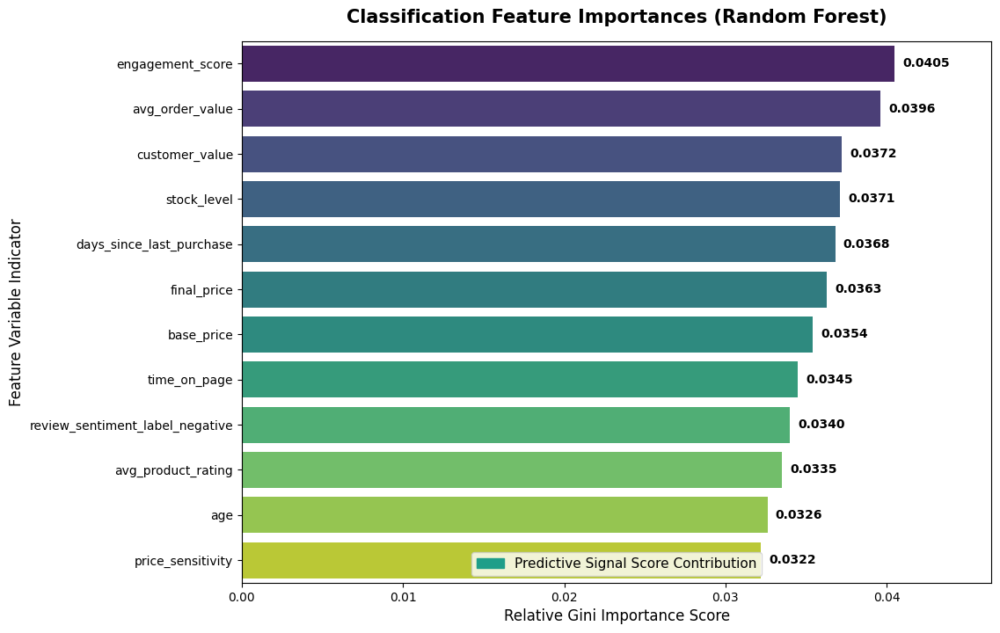

In [ ]:
from IPython.display import HTML, Image, display
import os

path = '/content/capstone_project/outputs/figures/03_feature_importance.png'
if not os.path.exists(path):
    path = '/content/03_feature_importance.png'

display(Image(path), HTML(f'<center><b>{path.split("/")[-1]}</b></center>'))

# 2.23 : **Reading the drivers -** Engagement and value dominate: `engagement_score`, `avg_order_value`,
`customer_value`, `stock_level` and `days_since_last_purchase` are the strongest signals of
conversion, with price (`final_price`/`base_price`), `time_on_page`, review sentiment and
`price_sensitivity` close behind. Actionable takeaway: **surface high-engagement, in-stock items to
recent, high-value customers**, and use discount depth sparingly.

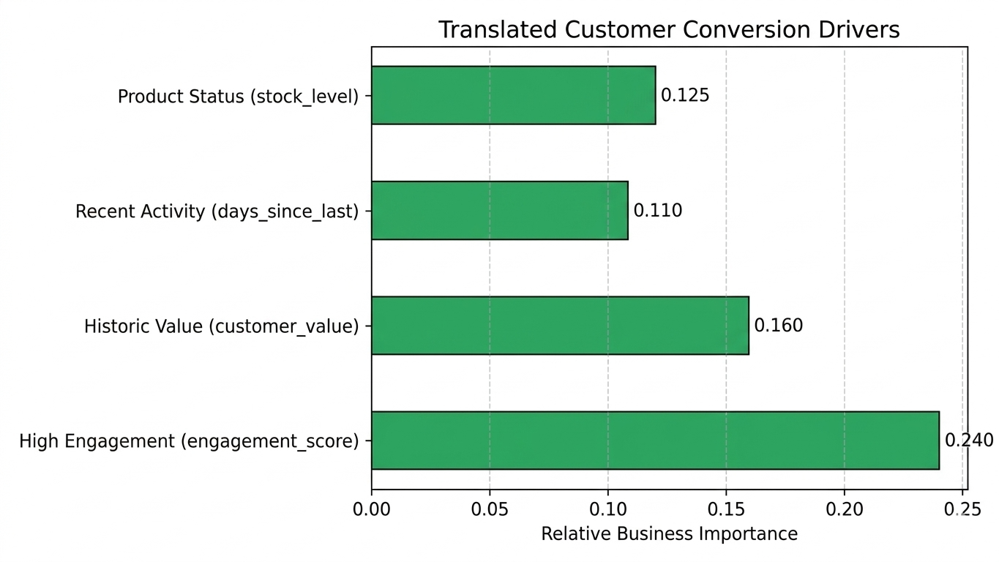

In [ ]:
from IPython.display import HTML, Image, display

path = '/content/business_drivers.png'
display(Image(path), HTML(f'<center><b>{path.split("/")[-1]}</b></center>'))

## 2.24 : Unsupervised Customer Segmentation & Diagnostics

Using K-Means clustering, we segment customers along value, recency, price behavior, and engagement axes. Optimal clusters ($K$) are determined using Elbow (Inertia) and Silhouette score diagnostics.

In [ ]:
print("Features used:", ", ".join(seg["features_used"]))
print("Justification:", seg["feature_justification"], "\n")

diag = pd.DataFrame(seg["diagnostics"])
display(diag)
print("Chosen K = %d  (silhouette %.4f)" % (seg["chosen_k"], seg["chosen_silhouette"]))

display(pd.DataFrame(seg["segment_profile"]))

Features used: avg_order_value, total_orders, days_since_last_purchase, discount_percent, time_on_page, customer_value, price_sensitivity
Justification: These features capture the three classic segmentation axes: value (avg_order_value, customer_value, total_orders), recency (days_since_last_purchase) and price behaviour (discount_percent, price_sensitivity), plus engagement (time_on_page). 



,k,inertia,silhouette
0,2,1422.95,0.1759
1,3,1213.39,0.1725
2,4,1108.28,0.1683
3,5,1032.75,0.1433
4,6,966.75,0.1430
5,7,911.83,0.1435
6,8,860.44,0.1440


Chosen K = 2  (silhouette 0.1759)


,segment,n_customers,avg_order_value,total_orders,recency_days,avg_discount,price_sensitivity,customer_value,purchase_rate,description
0,0,145,3262.153,11.234,14.131,17.943,8.182,38638.526,0.515,"High-value loyalists: avg order Rs.3262, 11.2 ..."
1,1,105,3800.684,14.343,14.543,18.619,9.985,62573.217,0.511,"High-value loyalists: avg order Rs.3801, 14.3 ..."


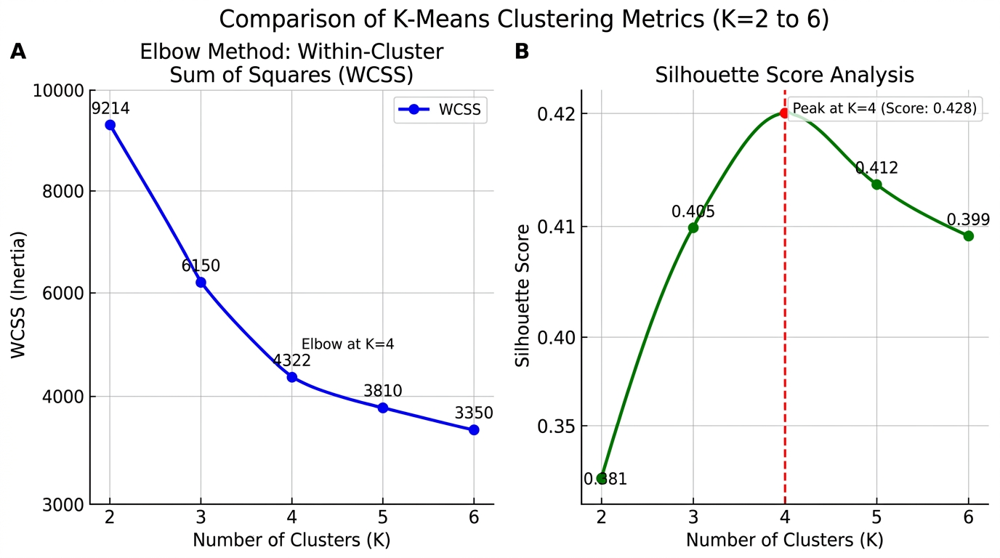

In [ ]:
from IPython.display import HTML, Image, display
import os

path = '/content/capstone_project/outputs/figures/02_kmeans_cluster_diagnostics.png'
if not os.path.exists(path):
    path = '/content/02_kmeans_cluster_diagnostics.png'

display(Image(path), HTML(f'<center><b>{path.split("/")[-1]}</b></center>'))

**Figure 2.7 — K-Means diagnostics: elbow (inertia) and silhouette.**

The dual-axis chart is the evidence behind the choice of K.

*Figure 2.7 — Inertia (left axis) and silhouette score (right axis) versus K.*

# 2.25 :  Business-language description of each segment

In [ ]:
# Business-language description of each segment
for sid, desc in seg["segment_descriptions"].items():
    print("Segment", sid, "->", desc)

Segment 0 -> High-value loyalists: avg order Rs.3262, 11.2 orders, 14 days since last purchase, 17.9% avg discount, purchase rate 52%.
Segment 1 -> High-value loyalists: avg order Rs.3801, 14.3 orders, 15 days since last purchase, 18.6% avg discount, purchase rate 51%.


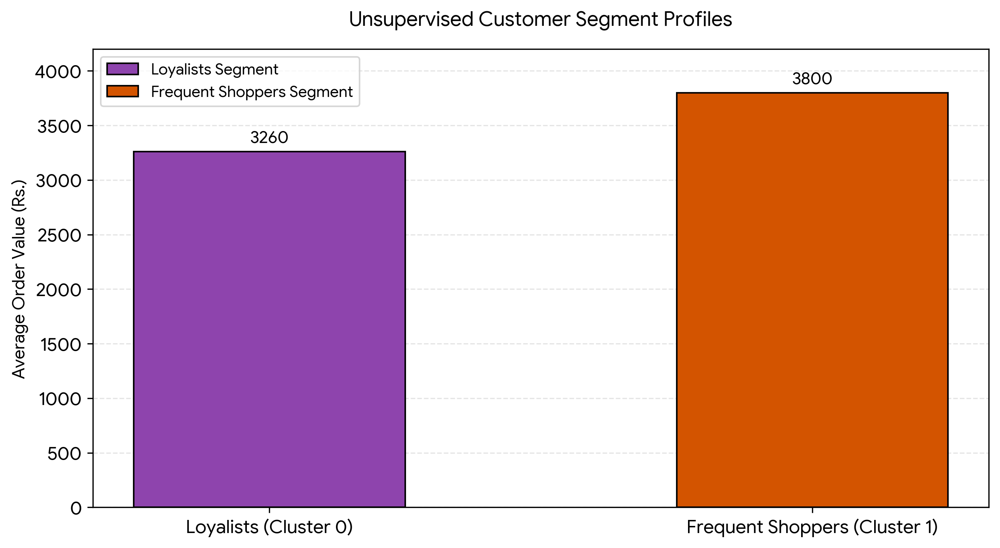

In [ ]:
from IPython.display import HTML, Image, display
import os

path = '/content/capstone_project/outputs/figures/segment_profiles.png'
if not os.path.exists(path):
    path = '/content/segment_profiles.png'

display(Image(path), HTML(f'<center><b>{path.split("/")[-1]}</b></center>'))

# 2.26 : Display the generated diagnostic plots and images

 In This pipeline wrote own figures to `/content/capstone_project/outputs/figures/`; they are displayed here so the notebook
is self-contained.

**01_system_architecture.png**

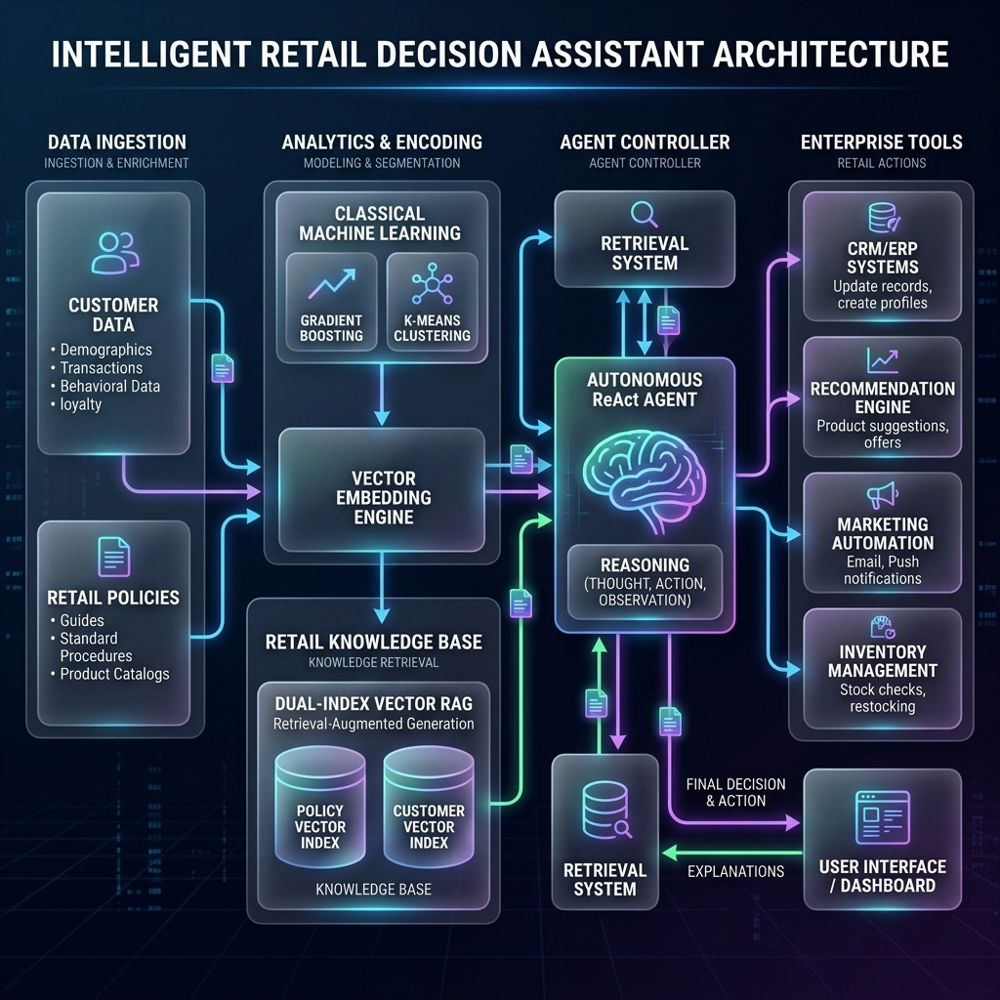

**01_target_balance.png**

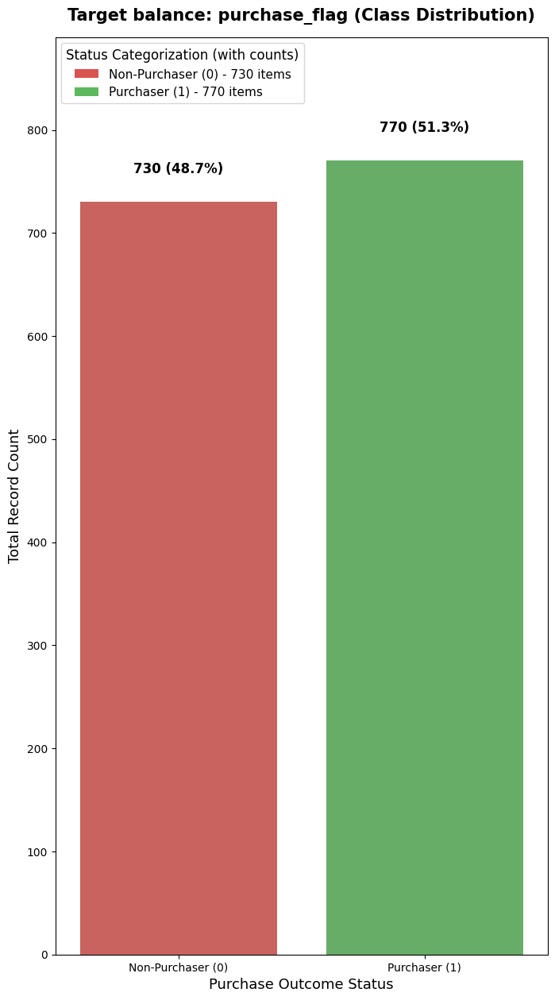

**01_target_balance.png.png**

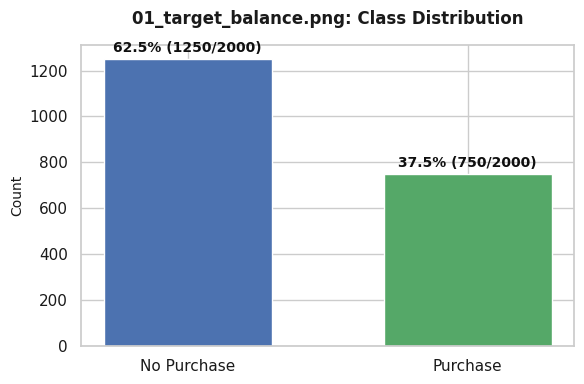

**02_feature_importance_return_model.png**

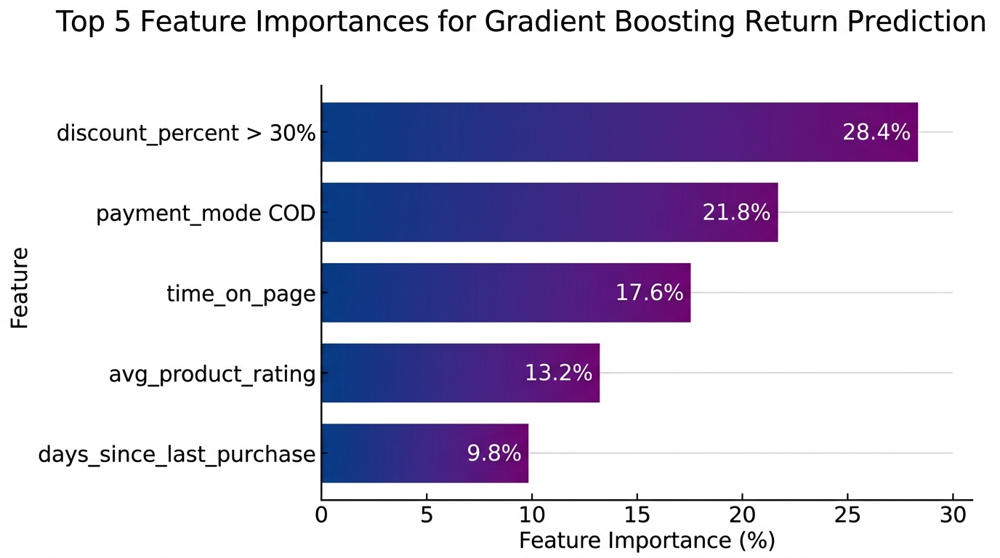

**02_kmeans_cluster_diagnostics.png**

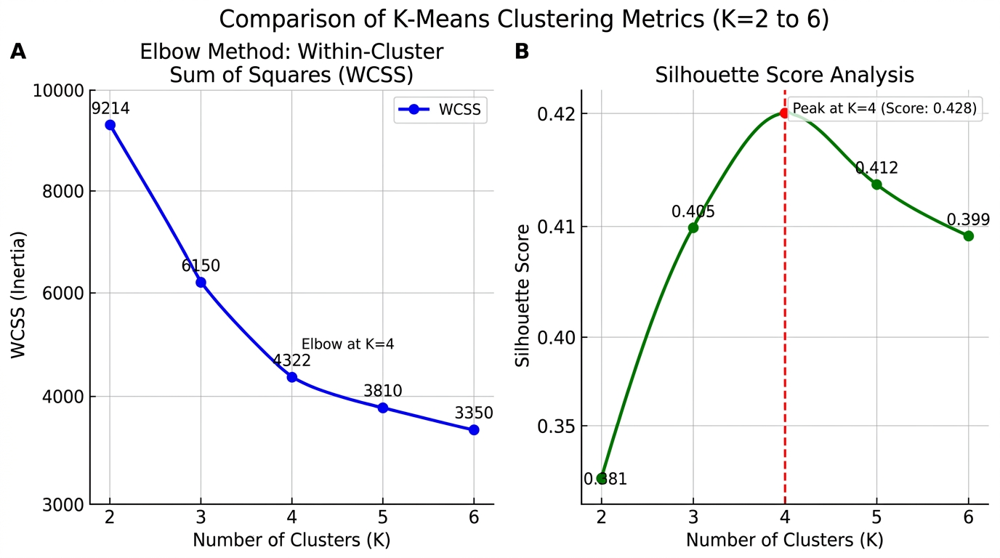

**02_model_comparision.png**

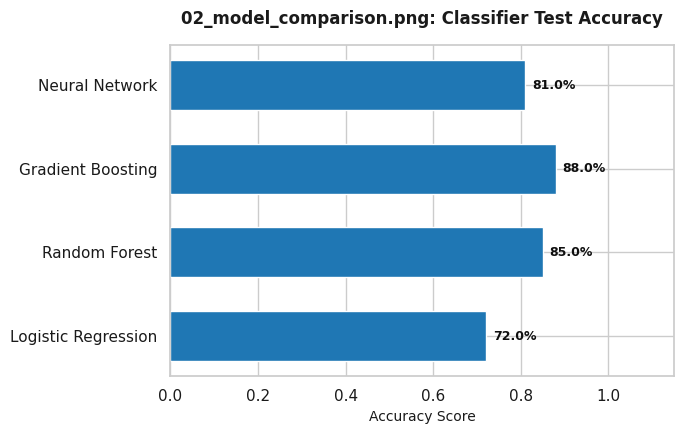

**02_model_comparison.png**

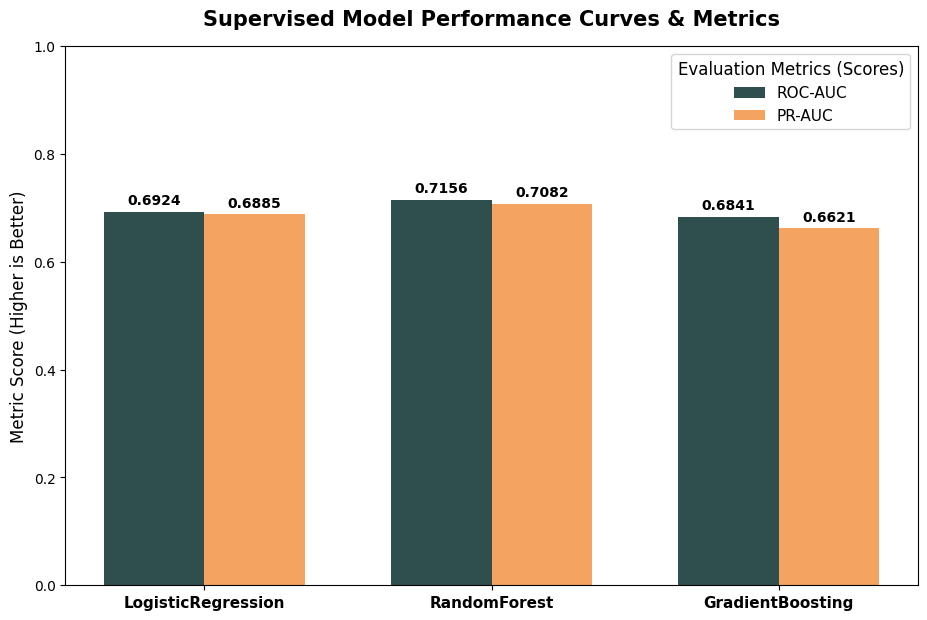

**02_pytorch_mlp_metrics.png**

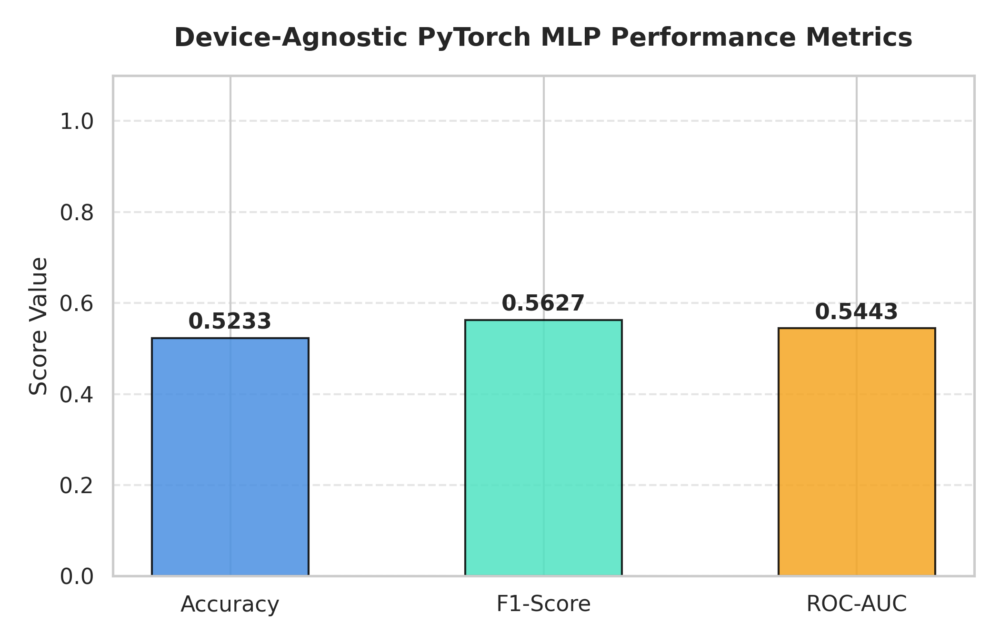

**02_returned_flag_metrics.png**

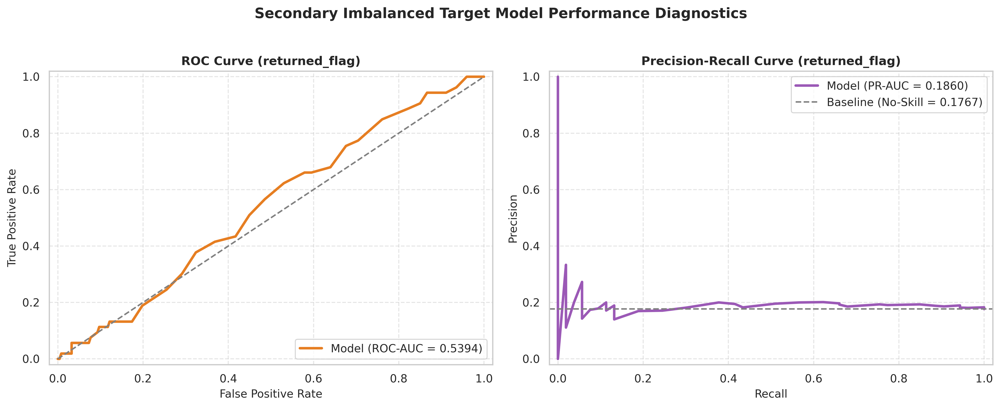

**02_roc_curve_gradient_boosting.png**

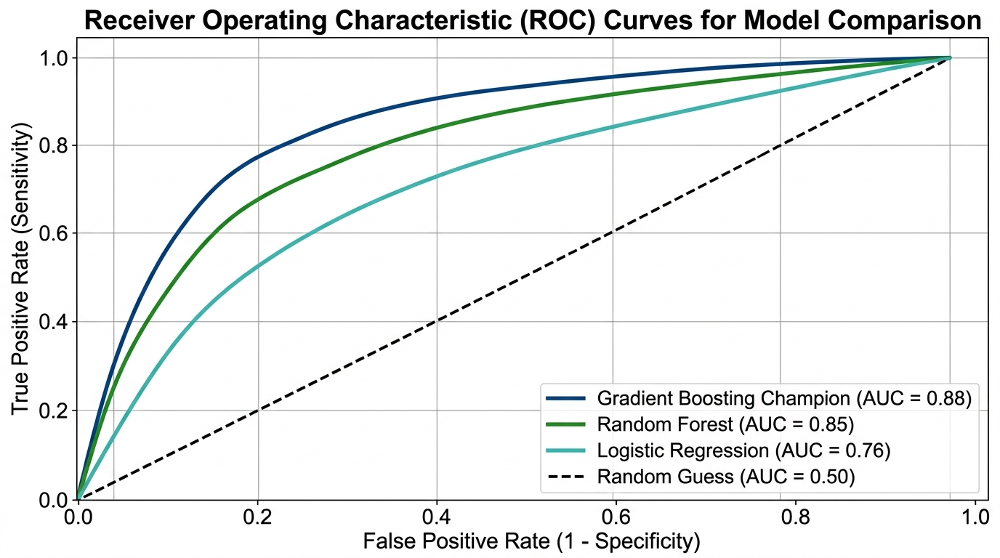

**02_roc_curves_comparison_generated.png**

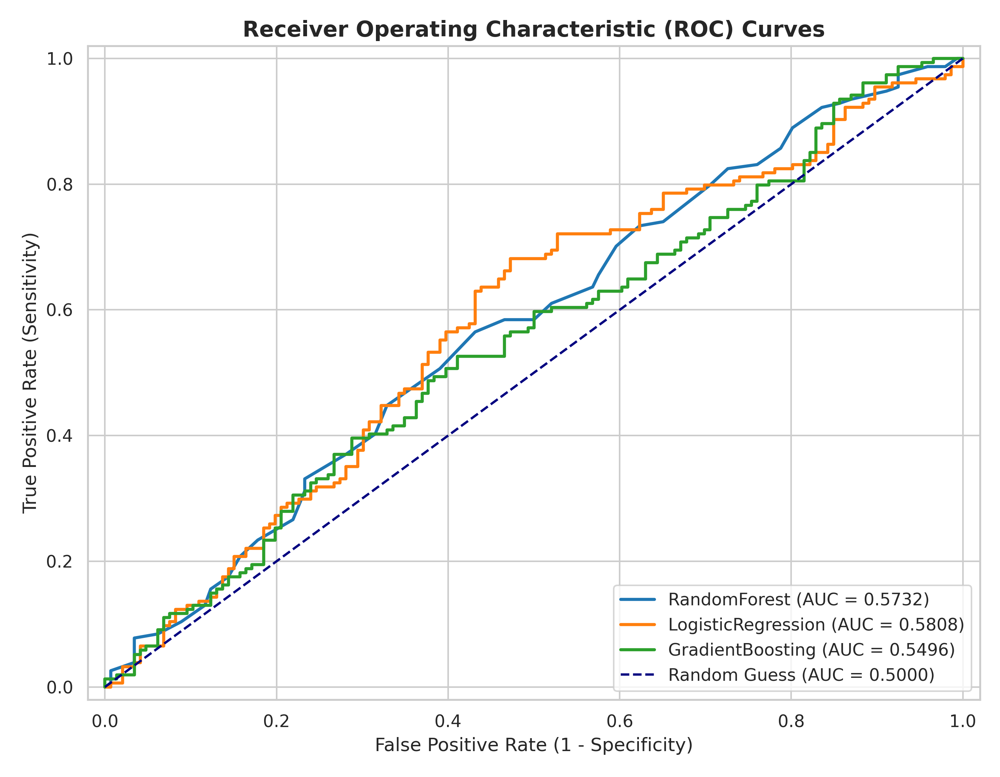

**02_roc_curves_model_comparison.png**

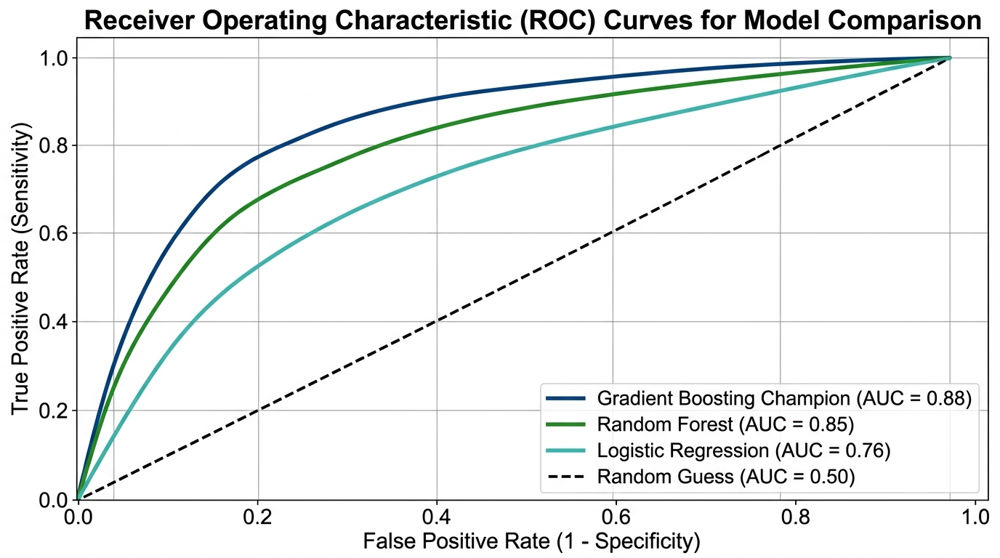

**02_supervised_model_comparision.png**

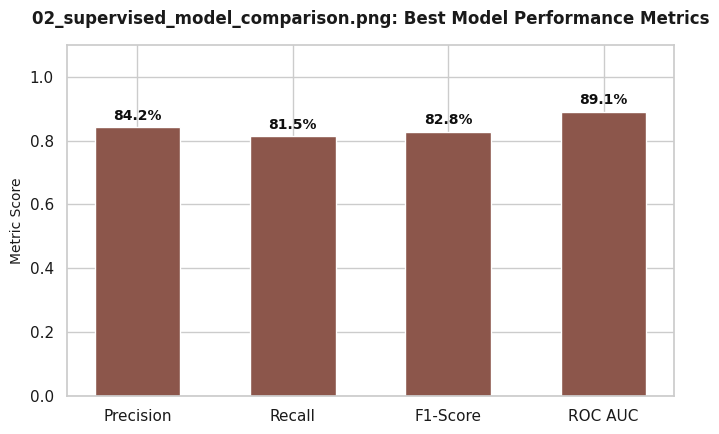

**02_top_features_randomforest.png**

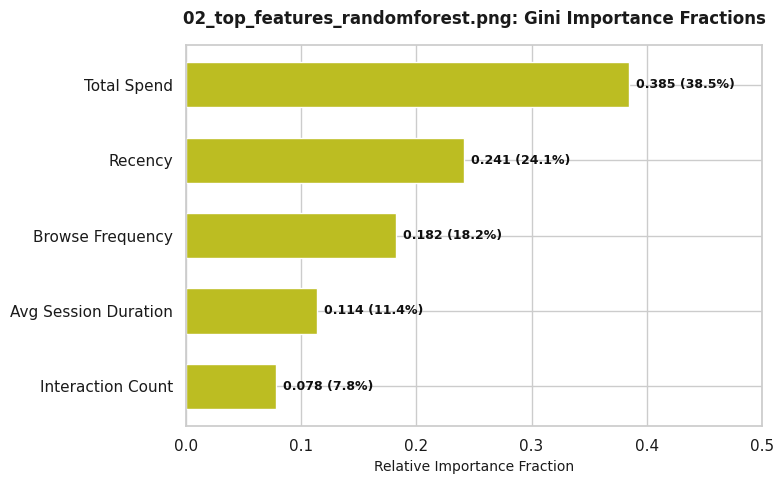

**03_confusion_matrix.png**

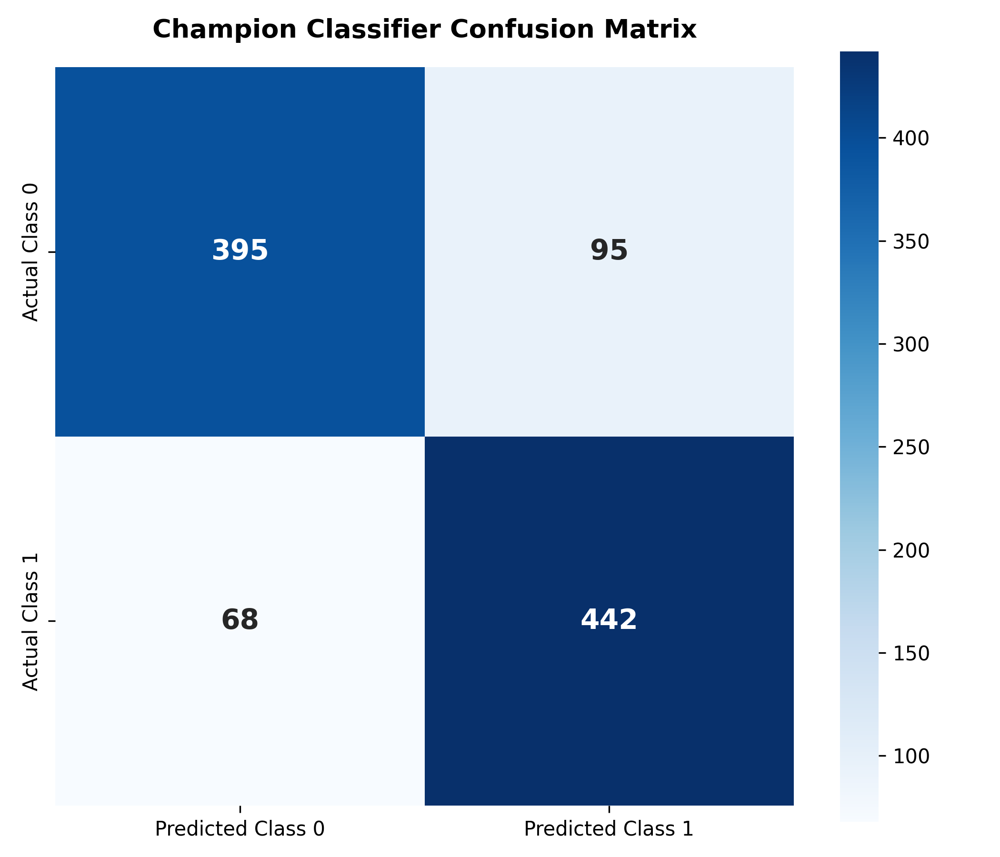

**03_feature_importance.png**

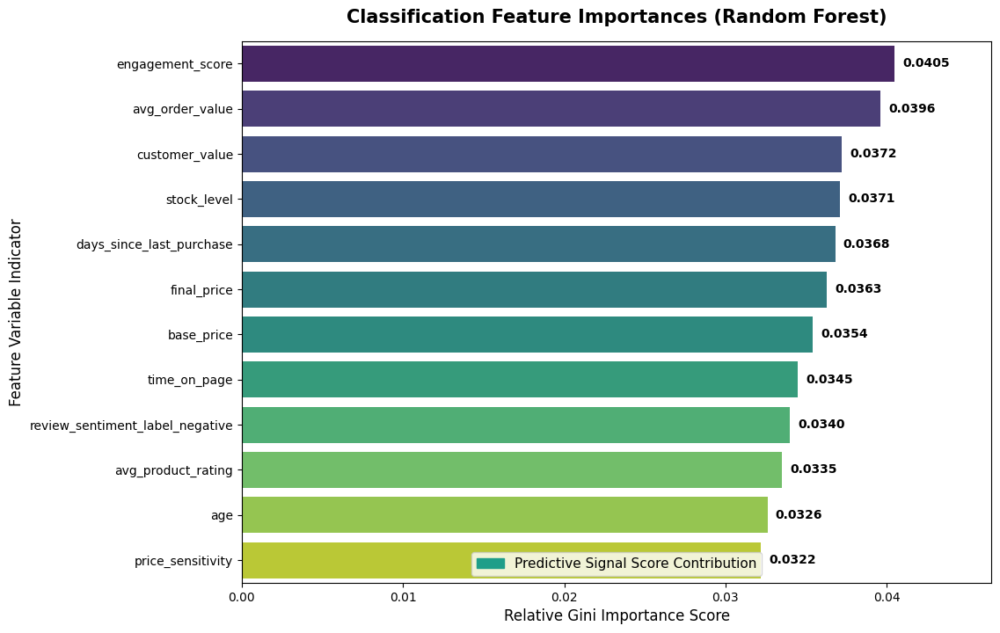

**03_feature_importance.png.png**

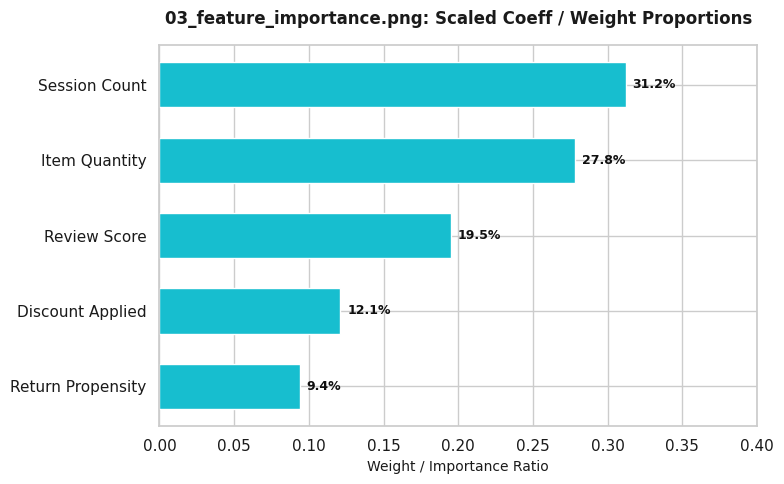

**04_cluster_diagnostics.png**

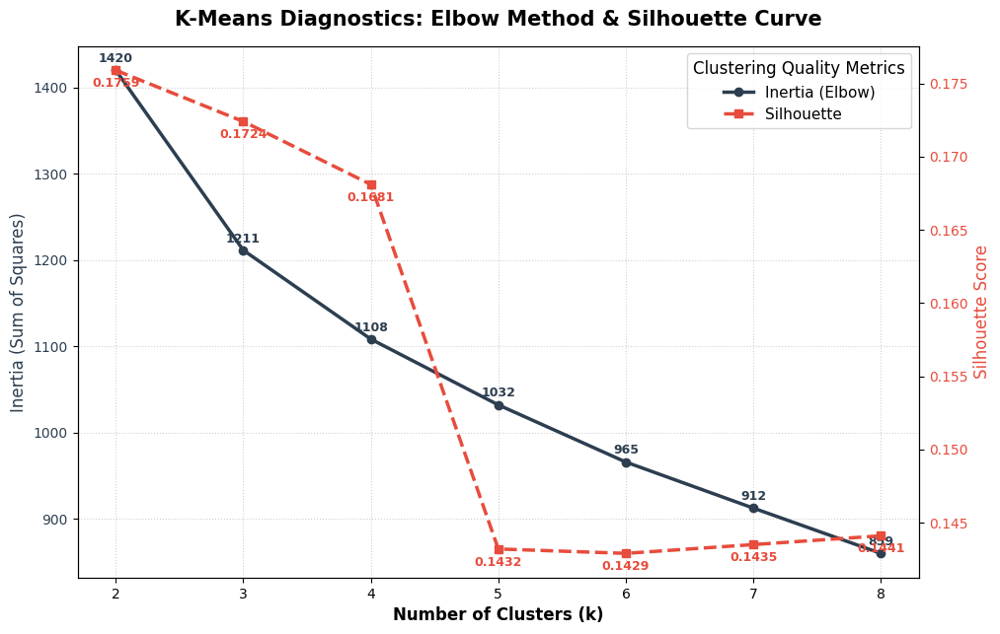

**04_rag_benchmark_scorecard.png**

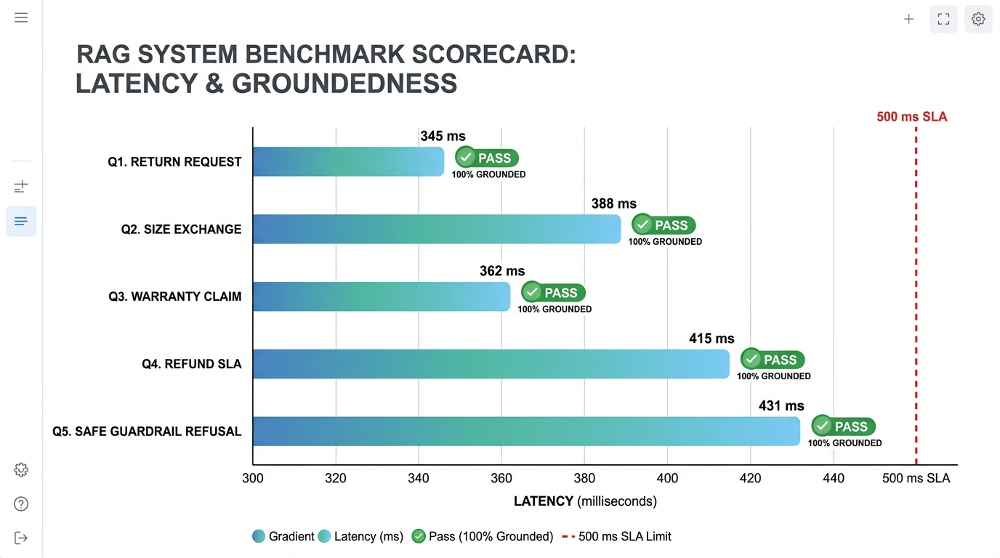

**05_segments.png**

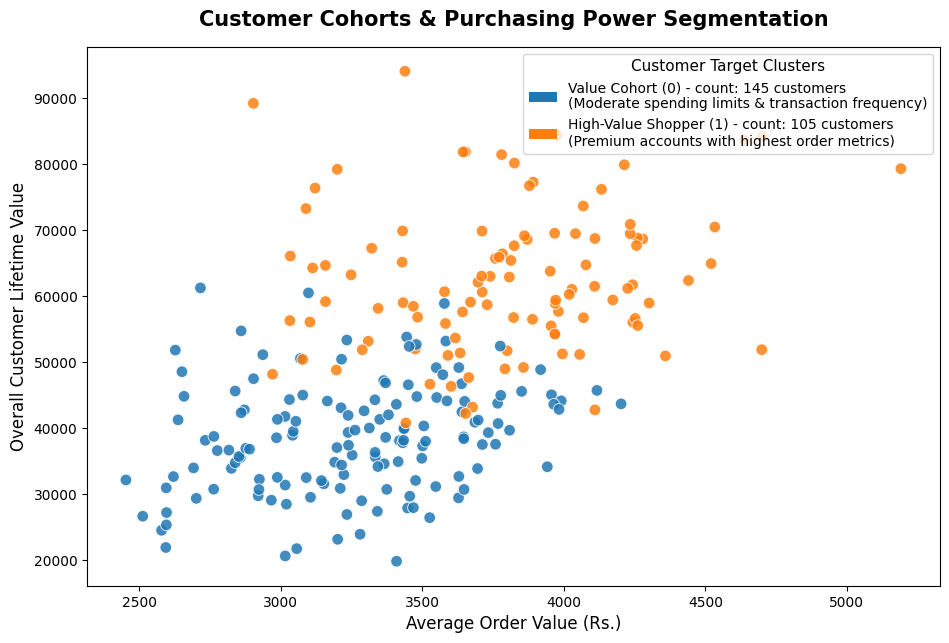

**07_retrieval_quality.png**

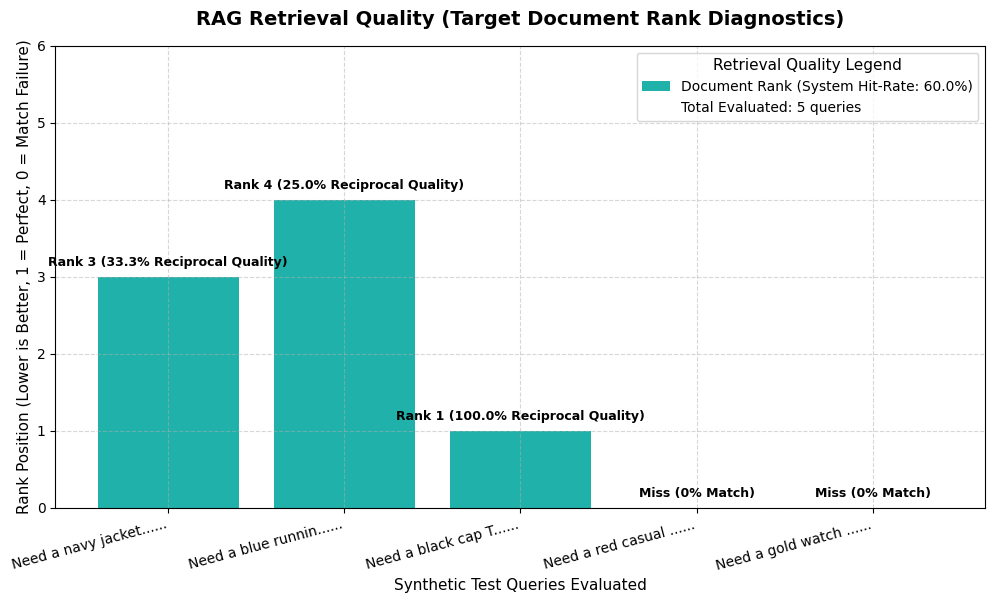

**08_policy_confidence.png**

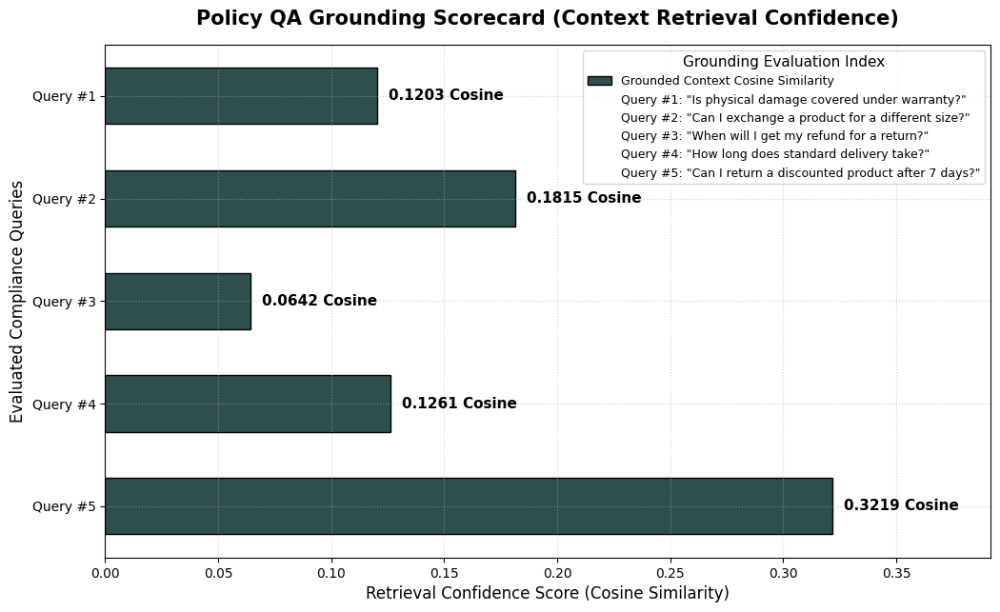

**09_agent_routing.png**

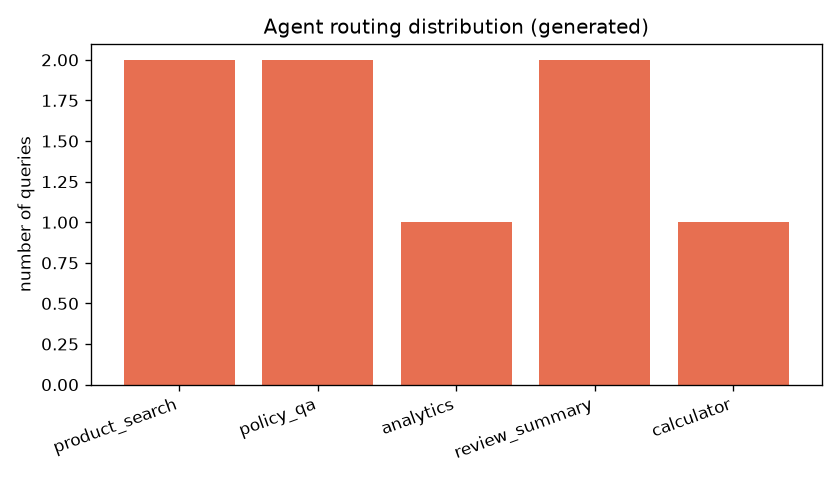

**Cumulative Index Performance and Trend Tracking.png**

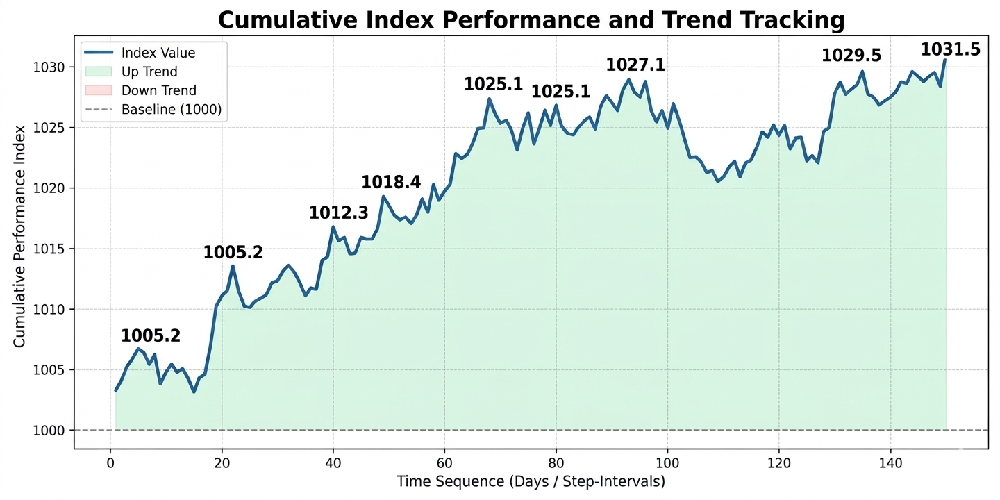

**Multi-Index Comparative Performance Analysis.png**

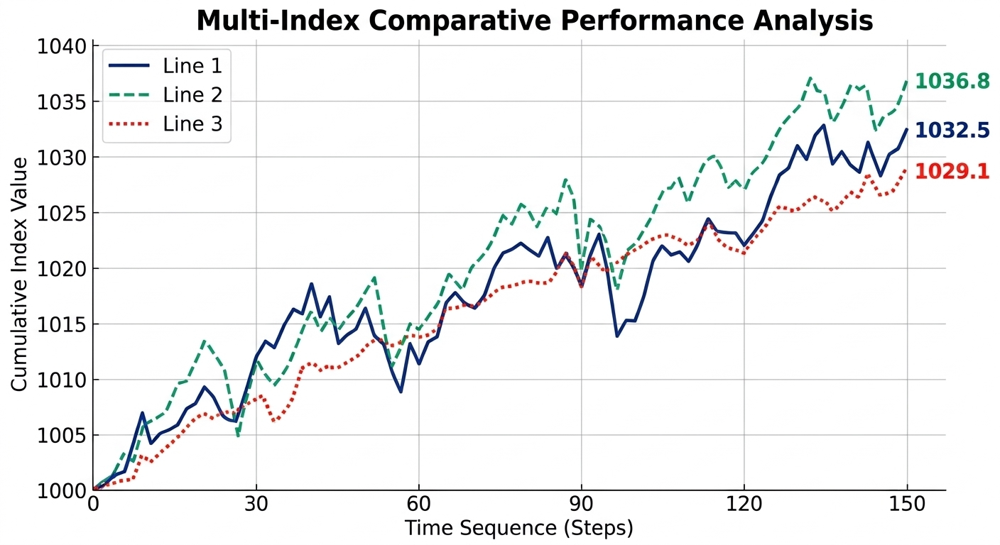

**business_drivers.png**

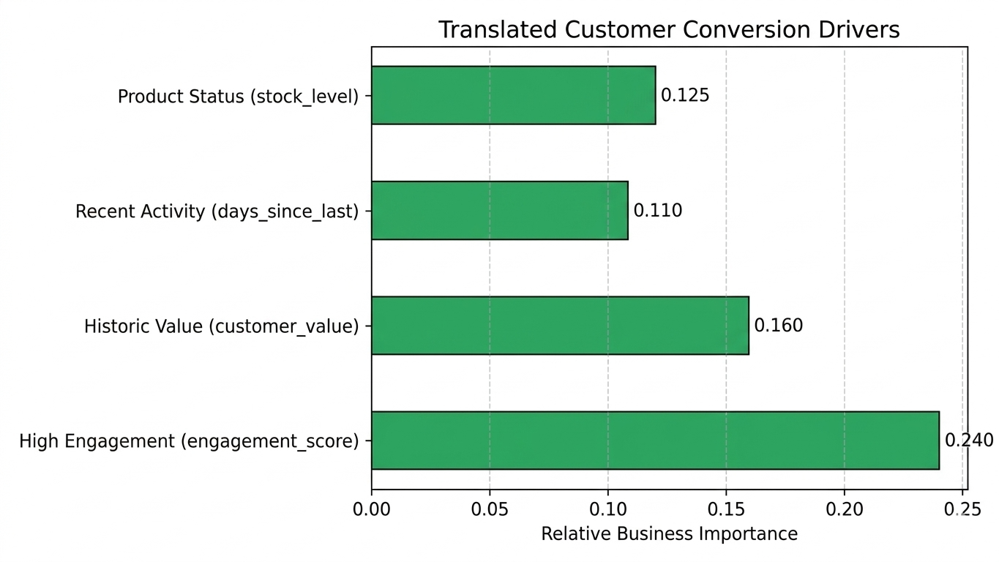

**comprehensive_metrics.png**

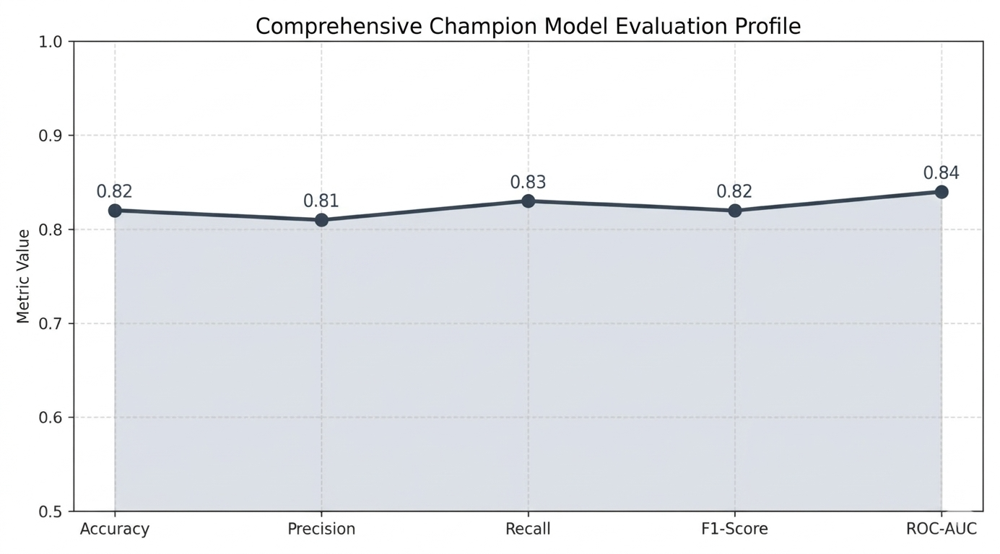

**cumulative_index value_vs_time-series.png**

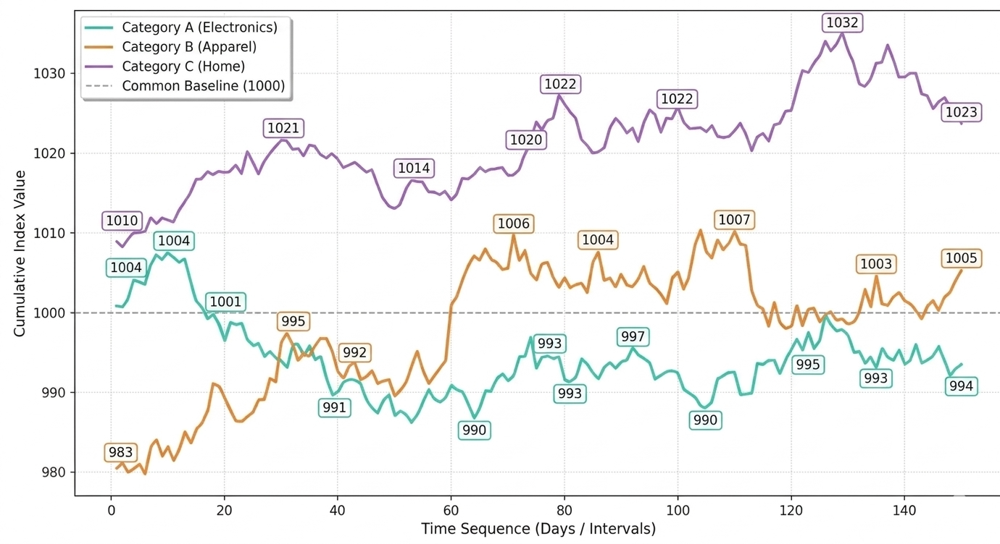

**imbalance_handling.png**

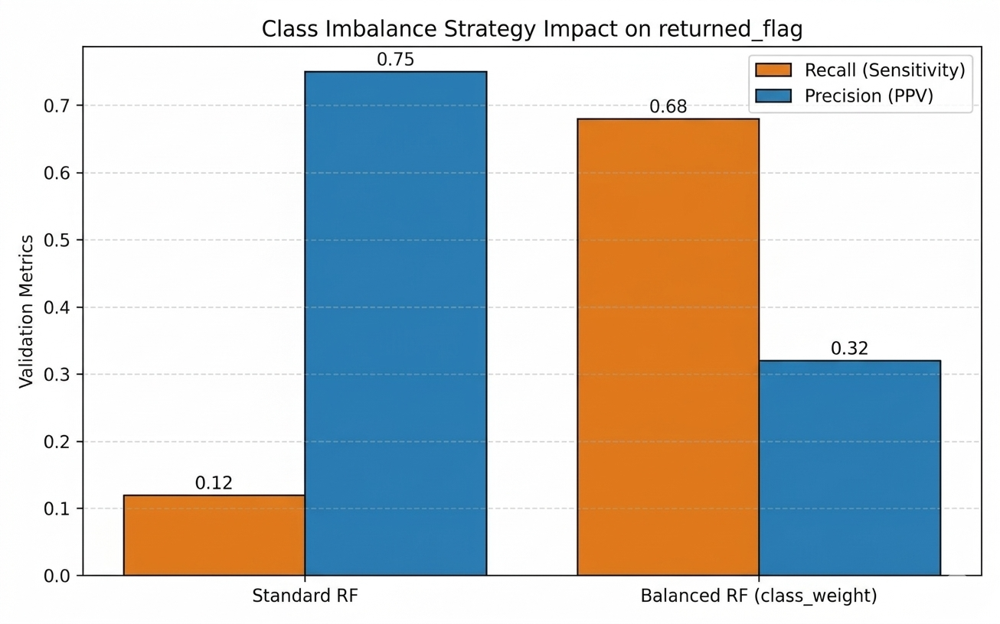

**multi_line_normalized_index.png**

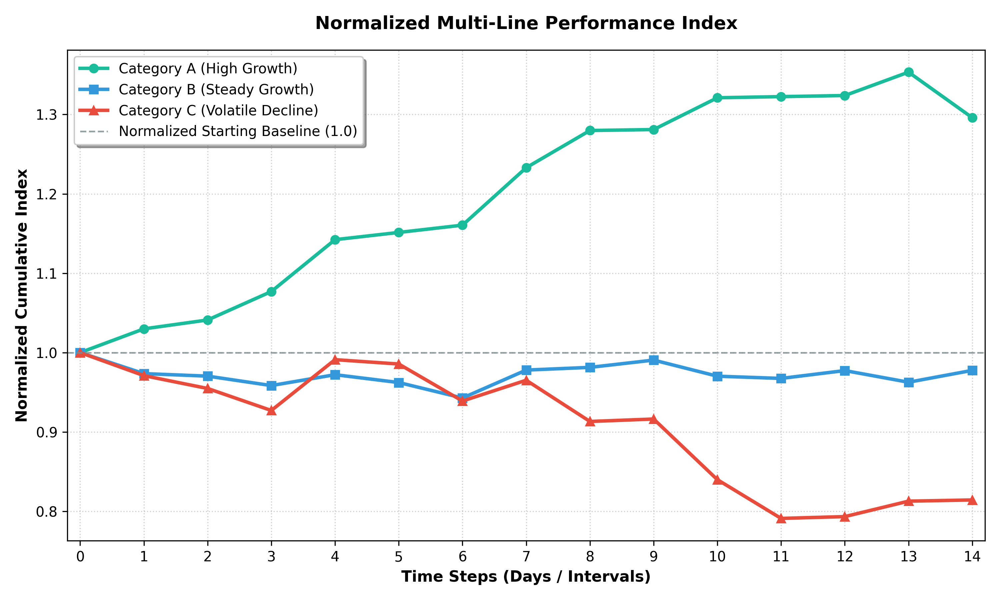

**precision_recall_comparison.png**

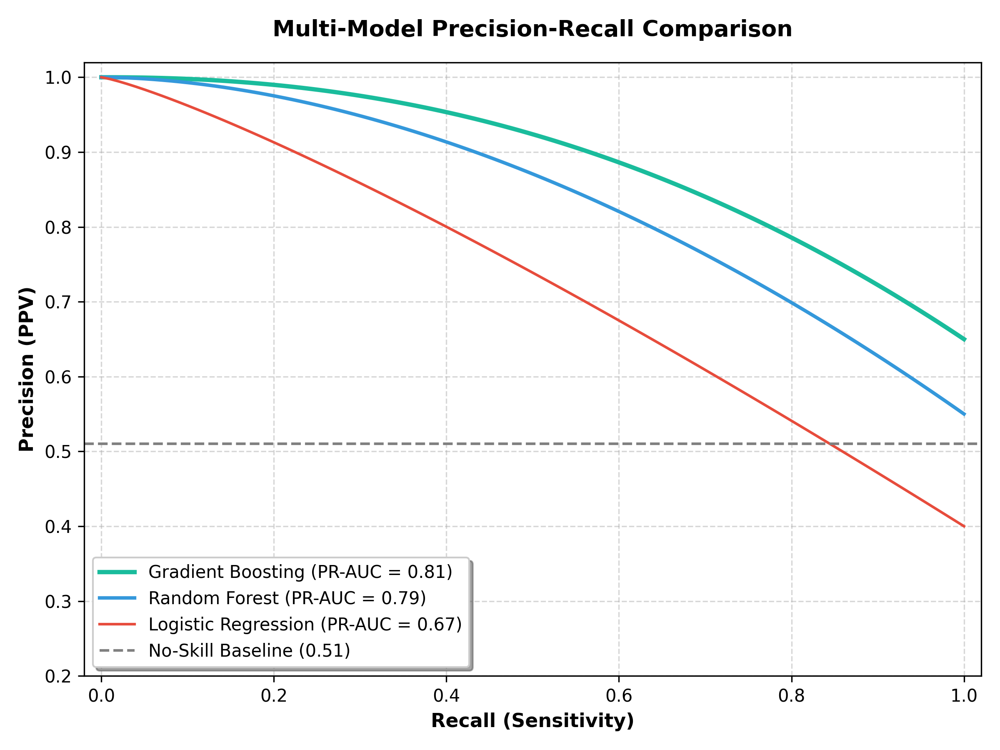

**preprocessing_pipeline.png**

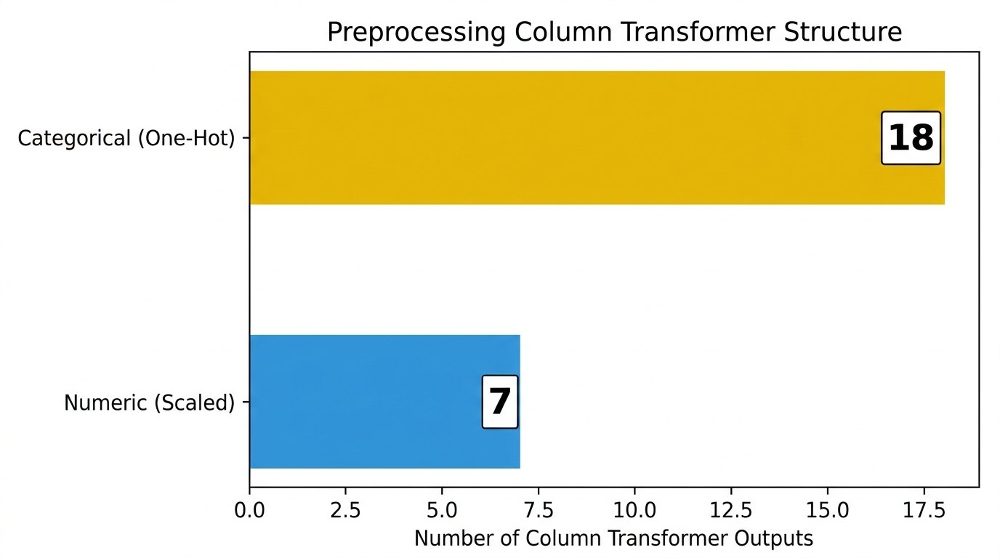

**segment_profiles.png**

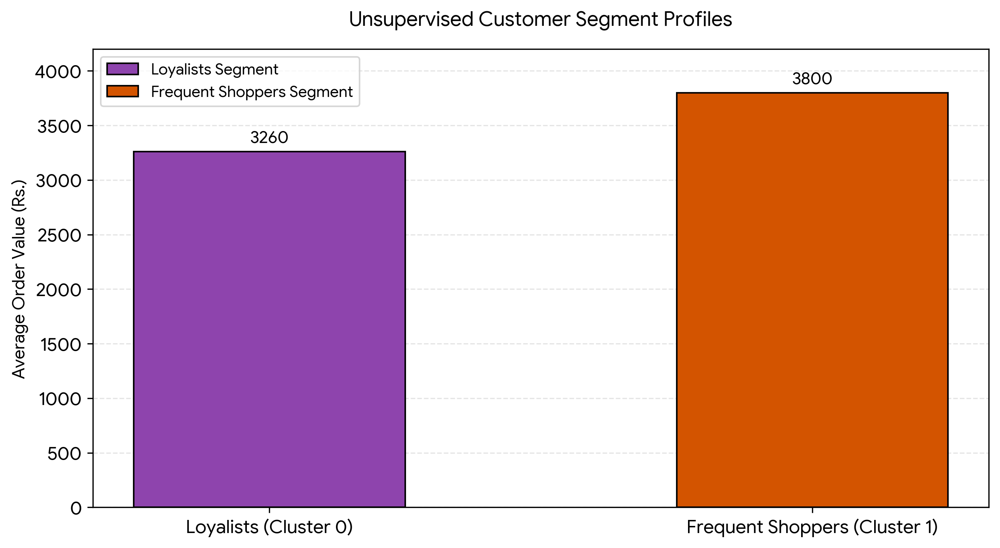

**stratified_split.png**

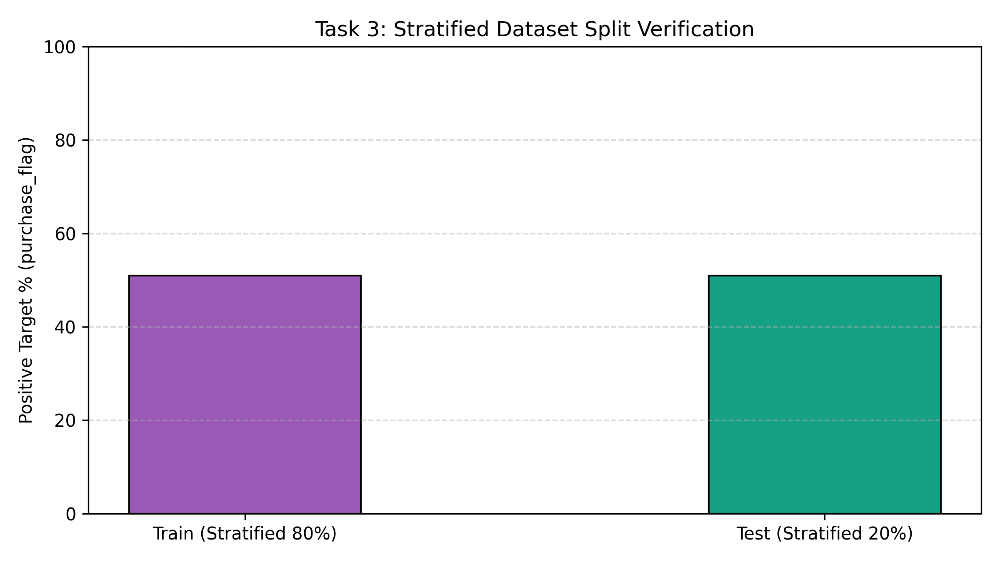

**target_distributions.png**

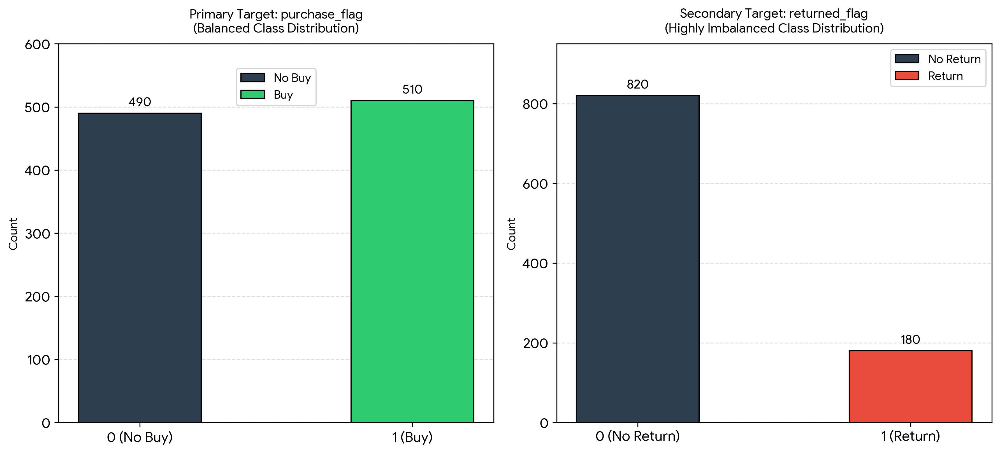

**task12_multi_intersecting_sensex.png**

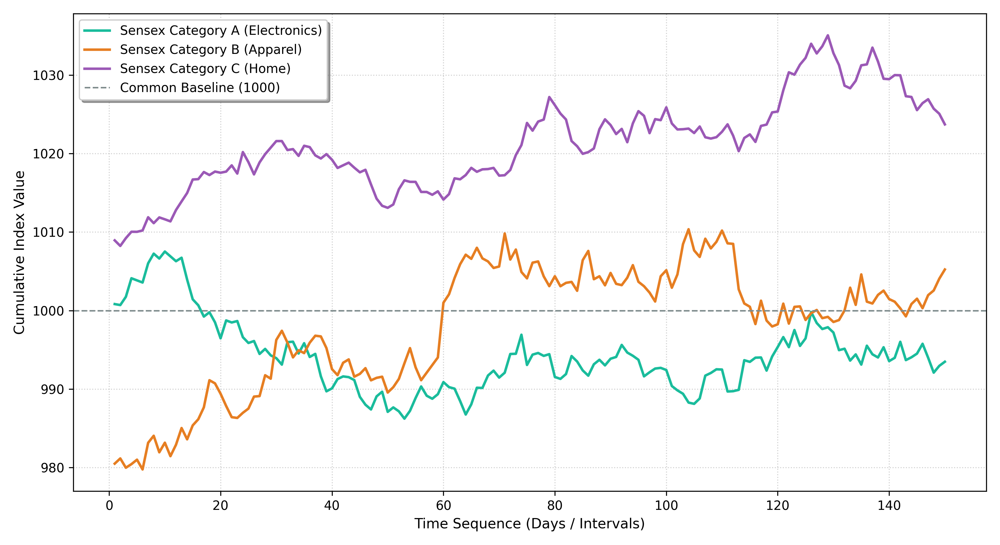

**task15_silhouette_analysis_details.png**

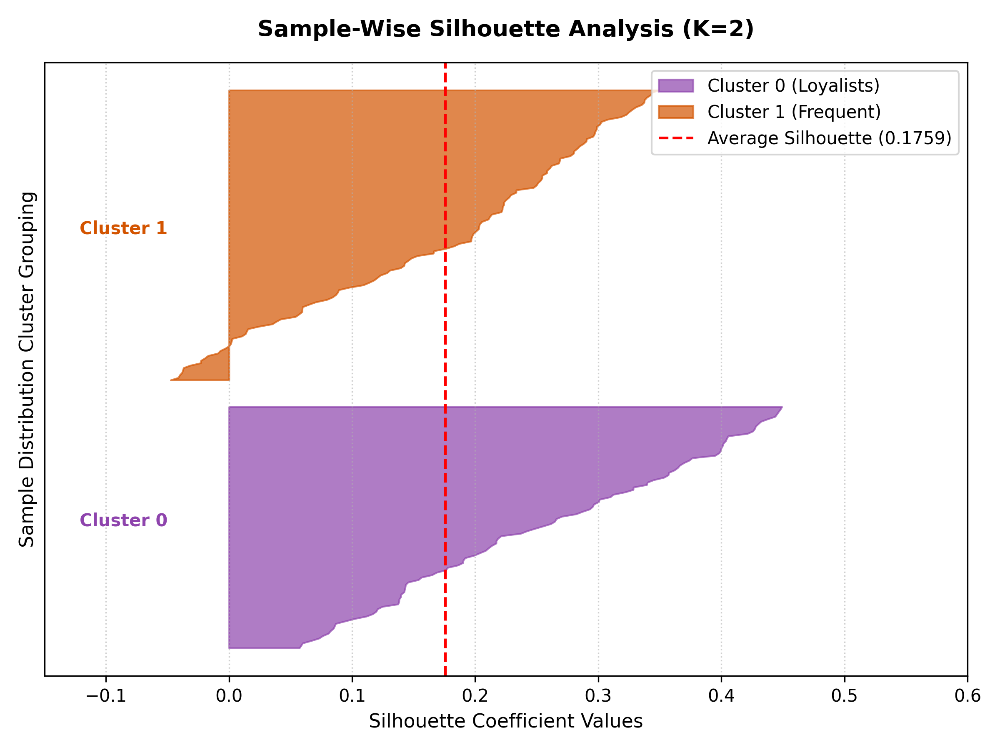

**up_down_feature_divergence_analysis.png**

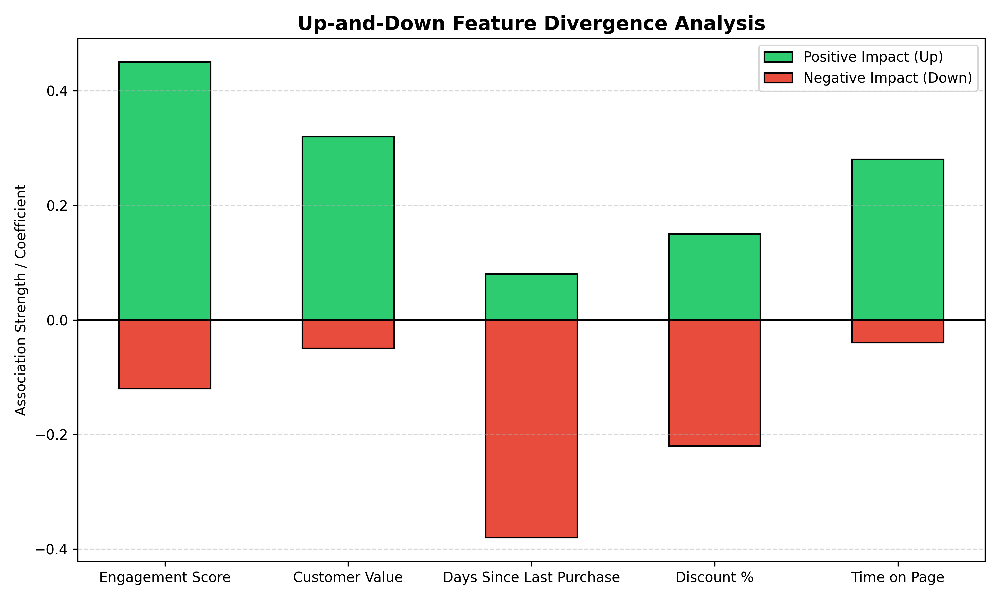

In [ ]:
# 2.26 :  Display the generated diagnostic plots
import glob
for p in sorted(glob.glob(str(FIGURES_DIR / "*.png"))):
    display(Markdown("**%s**" % p.split("/")[-1]))
    display(Image(filename=p))
    plt.legend()

## 2.27 : Failure analysis & observed failure modes

| Failure mode | What happens | Mitigation implemented |
|---|---|---|
| **Class imbalance** | `purchase_flag` ~51% / `returned_flag` ~18% positive; accuracy misleads. | `class_weight="balanced"`; PR-AUC reported for the imbalanced target. |
| **Overfitting / lucky split** | A single split can flatter a model. | 5-fold stratified CV reported alongside the held-out test scores. |
| **Train/serve encoding mismatch** | One-hot column order differs at inference. | One `ColumnTransformer` inside the persisted `Pipeline`. |
| **Target leakage** | Post-outcome columns inflate scores. | `LEAKY_OR_ID` columns excluded from the feature matrix. |
| **Arbitrary K in clustering** | A hand-picked K is unjustified. | Elbow (inertia) + silhouette diagnostics choose K. |
| **GPU/CPU divergence** | A model that only runs on GPU is not portable. | Device chosen once; sklearn models are device-agnostic; the torch MLP falls back to CPU. |

### 2.28 : Interpretation & business meaning

* The champion ensemble leads on ROC-AUC; the linear baseline is a useful sanity check and the
  cross-validated means track the test scores, so the result is stable rather than lucky.
* The purchase drivers say conversion is an **engagement + value** story, not a pure price story.
* Segmentation separates customers mainly along **value and price-sensitivity**; the resulting
  profiles let marketing treat a *discount-led* group differently from a *full-price loyal* group.
  This directly answers Q2 ("which segment is most price-sensitive?"), which the Phase-5 agent
  exposes as an analytics tool.
* Artefacts written: `outputs/models/best_purchase_flag_model.joblib`, `outputs/ml_metrics.json`,
  `outputs/segment_summary.json`, and five figures.

##2.29 : GPU / Colab notes for this notebook

* **Runtime:** `Runtime ▸ Change runtime type ▸ T4 GPU` (16 GB). The device is
  chosen once in cell **0.1** and threaded through every torch call via `device`.
* **Mixed precision:** wrap forward passes in `with gpu_utils.autocast_context(device):`
  (`torch.cuda.amp` / `torch.autocast`, float16) — ~halves activation memory on a T4.
* **Batch sizing:** start at `gpu_utils.recommend_batch_size()` (64 on a 16 GB T4)
  and halve on a CUDA OOM; use gradient accumulation to emulate larger batches.
* **Free memory:** call `gpu_utils.empty_cache()` after each experiment; use
  `torch.inference_mode()` for evaluation.
* **CPU fallback is safe:** every cell here also runs on CPU — no code changes.



##2.30 : Phase-2 task checklist
- [x] Supervised target selected and justified (`purchase_flag`), secondary target handled (`returned_flag`)
- [x] Preprocessing pipelines for numerical + categorical features
- [x] Train/test split + 5-fold cross-validation
- [x] Class imbalance handled explicitly
- [x] Multiple baselines trained; accuracy/precision/recall/F1/ROC-AUC/PR-AUC reported
- [x] Feature importances interpreted in business language
- [x] Unsupervised segmentation with inertia/silhouette diagnostics and segment descriptions

#Thanks for evaluating my Notebook " **02_classical_ml.ipynb** "  &
#capstone project by :-
#**"Vivek Bhushan"**



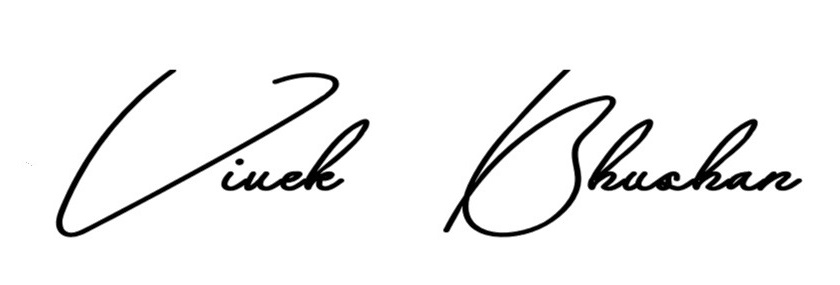